# Proyecto ML - Parte 2
Jose Manuel Fonseca, Julian Pinto y Daniel Vergara

## Contexto y objetivo
Vamos a clasificar reseñas como positivas, negativas o neutrales usando aprendizaje profundo. Esta vez hay textos en español, inglés, portugués, francés y mezclas de español e inglés. También aparecen ironía, negaciones y opiniones indirectas.

Compararemos un modelo sin aumento de datos con el mismo modelo entrenado con aumento. Revisaremos accuracy, F1 y errores por idioma. No usaremos eval para entrenar ni para generar etiquetas con una API.

El enunciado anuncia 20.466 reseñas de entrenamiento y 6.781 de evaluación. Los datos de la primera parte no sustituyen estos archivos.


## Ejecutar en Google Colab
La siguiente celda solo actúa en Colab; en el `.venv` local no hace nada.

1. **Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU** (o cualquier GPU disponible).
2. Ejecutar la celda. Monta Google Drive, clona el repositorio en `MyDrive/ISIS-2611-Proyecto-Parte-2` si todavía no existe y trabaja ahí, de modo que los CSV y los `.pt` generados quedan guardados en Drive aunque se cierre la sesión.
3. Instala `langid`, `scikit-learn`, `scipy`, `transformers` y `sentence-transformers` con las versiones registradas localmente, porque la partición se recalcula y se compara con `particiones.csv`. Si la celda pide reiniciar la sesión, reiniciar y volver a ejecutarla.
4. Después, **Entorno de ejecución > Ejecutar todas**. El modelo 2 depende de variables del modelo 1, así que el notebook debe correr en orden.

En CUDA los resultados pueden diferir levemente de los obtenidos con MPS. Los números escritos en las celdas de texto corresponden a la ejecución local.

In [ ]:
# Preparacion para Google Colab. Fuera de Colab esta celda no hace nada.
import sys

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    import os
    import subprocess
    from importlib.metadata import version as version_instalada
    from pathlib import Path

    USAR_DRIVE = True  # False: trabajar en /content, que se borra al cerrar la sesion
    URL_REPO = 'https://github.com/jmfonsecau/ISIS-2611-Proyecto-Parte-2.git'
    if USAR_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        CARPETA_PROYECTO = Path('/content/drive/MyDrive/ISIS-2611-Proyecto-Parte-2')
    else:
        CARPETA_PROYECTO = Path('/content/ISIS-2611-Proyecto-Parte-2')
    if not (CARPETA_PROYECTO / 'train.csv').is_file():
        subprocess.run(['git', 'clone', '--depth', '1', URL_REPO, str(CARPETA_PROYECTO)], check=True)
    os.chdir(CARPETA_PROYECTO)
    print('Carpeta de trabajo:', Path.cwd())

    # Versiones de la ejecucion local: la particion se recalcula y debe coincidir con particiones.csv.
    FIJADAS = {'langid': '1.1.6', 'scikit-learn': '1.9.1', 'scipy': '1.18.1',
               'transformers': '4.57.3', 'sentence-transformers': '5.1.2'}
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    *[f'{paquete}=={v}' for paquete, v in FIJADAS.items()]], check=True)

    # pip puede actualizar paquetes que Colab ya importo; esos requieren reiniciar la sesion.
    modulos = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn',
               'transformers': 'transformers', 'sentence_transformers': 'sentence-transformers',
               'huggingface_hub': 'huggingface-hub', 'tokenizers': 'tokenizers'}
    desactualizados = [paquete for modulo, paquete in modulos.items() if modulo in sys.modules
                       and sys.modules[modulo].__version__ != version_instalada(paquete)]
    if desactualizados:
        raise RuntimeError(f'Se actualizaron {desactualizados}, pero la sesion conserva la version anterior. '
                           'Usar Entorno de ejecucion > Reiniciar sesion y volver a ejecutar esta celda.')

    import torch
    if torch.cuda.is_available():
        print('GPU:', torch.cuda.get_device_name(0))
    else:
        print('Sin GPU. Elegir Entorno de ejecucion > Cambiar tipo de entorno de ejecucion > T4 GPU.')


## Imports
Empezamos con las herramientas de revisión de datos. Añadiremos la librería de redes cuando elijamos la arquitectura y el entorno de entrenamiento.


In [2]:
from pathlib import Path
import hashlib
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

display(pd.Series({
    'Python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
}, name='Version'))


Python    3.12.13
numpy       2.5.3
pandas      3.0.6
Name: Version, dtype: str

## Carga y comprobación de archivos
Los tres CSV de la nueva competencia deben estar junto al notebook. Comprobamos su tamaño antes de continuar para no mezclar las dos partes. Si Kaggle publica una corrección de los datos, revisaremos estos valores con la nueva versión.


In [3]:
CARPETA_DATOS = Path('.')
nombres = ['train.csv', 'eval.csv', 'sample_submission.csv']
faltantes = [nombre for nombre in nombres if not (CARPETA_DATOS / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan los CSV de Parte 2: {faltantes}')

train = pd.read_csv(CARPETA_DATOS / 'train.csv')
eval_df = pd.read_csv(CARPETA_DATOS / 'eval.csv')
plantilla = pd.read_csv(CARPETA_DATOS / 'sample_submission.csv')

display(pd.DataFrame({
    'archivo': nombres,
    'filas': [len(train), len(eval_df), len(plantilla)],
    'esperadas': [20466, 6781, 6781],
}))
if (len(train), len(eval_df), len(plantilla)) != (20466, 6781, 6781):
    raise ValueError('Los tamaños no coinciden con el enunciado de Parte 2. Verificar la descarga antes de entrenar.')

assert set(train.columns) == {'id', 'text', 'label'}
assert set(eval_df.columns) == {'id', 'text'}
assert list(plantilla.columns) == ['id', 'answer']
assert train['label'].isin(['negativo', 'neutral', 'positivo']).all()
assert train['id'].notna().all() and train['id'].is_unique
assert eval_df['id'].notna().all() and eval_df['id'].is_unique
assert eval_df['id'].tolist() == plantilla['id'].tolist()

huellas_datos = {
    nombre: hashlib.sha256((CARPETA_DATOS / nombre).read_bytes()).hexdigest()
    for nombre in nombres
}
display(train.head())


,archivo,filas,esperadas
0,train.csv,20466,20466
1,eval.csv,6781,6781
2,sample_submission.csv,6781,6781


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral


## Revisión inicial
Revisaremos nulos, textos vacíos, identificadores y clases. No eliminaremos ni completaremos reseñas automáticamente antes de entender cada problema. Conservaremos tildes, puntuación, mayúsculas y negaciones como punto de partida: pueden aportar información en varios idiomas.


,train,eval
Textos nulos,0,0
Textos vacios o con espacios,0,0
Textos duplicados no nulos,0,0
Identificadores nulos,0,0
Identificadores repetidos,0,0


,Nulos por columna en train
id,0
text,0
label,0


,Cantidad,Porcentaje
label,,
positivo,7486,36.58
negativo,7381,36.06
neutral,5599,27.36


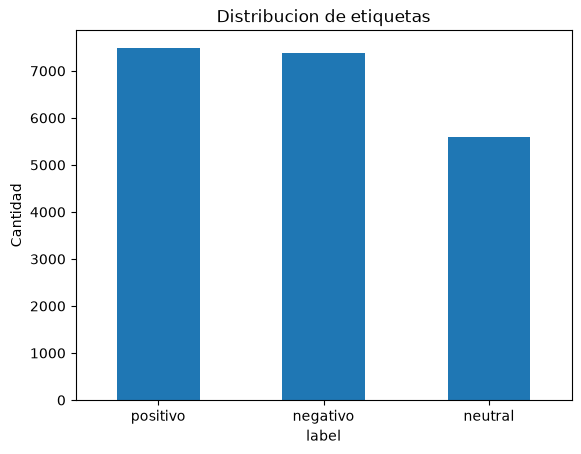

In [4]:
resumen = {}
for nombre, datos in [('train', train), ('eval', eval_df)]:
    textos = datos['text'].astype('string')
    resumen[nombre] = {
        'Textos nulos': textos.isna().sum(),
        'Textos vacios o con espacios': textos.str.strip().eq('').sum(),
        'Textos duplicados no nulos': textos.dropna().duplicated().sum(),
        'Identificadores nulos': datos['id'].isna().sum(),
        'Identificadores repetidos': datos['id'].duplicated().sum(),
    }
display(pd.DataFrame(resumen))
display(train.isna().sum().to_frame('Nulos por columna en train'))
conteos = train['label'].value_counts()
display(pd.DataFrame({
    'Cantidad': conteos,
    'Porcentaje': (conteos / len(train) * 100).round(2),
}))
conteos.plot.bar(title='Distribucion de etiquetas', rot=0, ylabel='Cantidad')
plt.show()


## Longitudes y coincidencias entre archivos

Comparamos longitudes por clase y buscamos textos iguales entre train y eval. Estas comprobaciones no usan etiquetas de eval ni permiten descartar por sí solas coincidencias aproximadas o traducciones.


In [5]:
textos_train = train['text'].astype('string')
textos_eval = eval_df['text'].astype('string')
display(pd.DataFrame({'Cantidad': [
    len(set(textos_train.dropna()) & set(textos_eval.dropna())),
    textos_train.str.lower().str.strip().dropna().duplicated().sum(),
]}, index=['Textos exactos compartidos train/eval',
          'Duplicados en train tras minusculas y espacios']))

longitudes = train.assign(palabras=textos_train.str.split().str.len())
display(longitudes.groupby('label')['palabras'].agg(
    ['count', 'mean', 'median', 'min', 'max']).round(2))


,Cantidad
Textos exactos compartidos train/eval,0
Duplicados en train tras minusculas y espacios,0


,count,mean,median,min,max
label,,,,,
negativo,7381,59.04,58.0,6,125
neutral,5599,53.16,53.0,3,100
positivo,7486,59.10,59.0,5,120


## Ejemplos de desarrollo

Leemos dos ejemplos por etiqueta para conocer las formas de expresar el sentimiento. Esta inspección no es una estimación de proporciones por idioma; el análisis multilingüe queda pendiente. La exploración inicial de train completo debe tenerse en cuenta al diseñar la validación.


In [6]:
for etiqueta in ['negativo', 'neutral', 'positivo']:
    print(f'\n{etiqueta.upper()}')
    ejemplos = train.loc[train['label'].eq(etiqueta), 'text'].sample(
        2, random_state=RANDOM_STATE)
    for numero, texto in enumerate(ejemplos, 1):
        print(f'{numero}. {texto}\n')



NEGATIVO
1. Compré esta carcasa hace un mes en una tienda de electrónica cerca de mi casa, la negra, porque la mía anterior se había roto con la mudanza. Doy mi punto de vista: la carcasa resultó veloz desde el primer día que la instalé en el escritorio. El envío no tardó nada y el peso me pareció normal. Aun así, la batería me resultó ser decepcionante para el precio que tiene.

2. Compré este reloj a inicios de mes en una tienda por departamentos del centro, pagué con tarjeta y me llegó en dos días. Hace un mes, lo uso a diario. La resistencia al agua me salió formidable en estas semanas, la probé en la alberca del club donde voy los sábados con mi cuñado. Con todo, la portabilidad me pareció terrible desde que lo estrené.


NEUTRAL
1. Lo compré a mediados de mes para usarlo aquí en casa, apenas llevo unos días con él. La entrega la hizo la mensajería de siempre y llegó en dos días, en la caja sellada. Lo dejé instalado en la sala y por ahora solo lo he usado por las tardes. Todavía

## Observaciones iniciales

Confirmamos los tamaños del enunciado y las columnas, etiquetas e identificadores esperados. No encontramos nulos, textos vacíos ni duplicados exactos dentro de cada archivo.

Distribución: negativo: 7,381 (36.06 %), neutral: 5,599 (27.36 %), positivo: 7,486 (36.58 %). Neutral tiene menos ejemplos, por lo que revisaremos también métricas por clase, no solo accuracy.

No se han eliminado filas, normalizado textos, generado aumentos ni entrenado modelos. Las siguientes secciones analizan idiomas y coincidencias cercanas para fijar la separación. La arquitectura sigue pendiente.


## Idiomas estimados

Usamos langid 1.1.6 localmente, limitado a es, en, pt y fr. No enviamos textos a una API. Es un modelo preentrenado auxiliar, no el clasificador de sentimiento. Su fuente y licencia BSD-2-Clause están en REFERENCIAS.md.

Si falta la dependencia, ejecutar `%pip install langid==1.1.6` en el kernel del notebook y reiniciarlo si es necesario.

La puntuación normalizada del detector no es una confianza calibrada con estas reseñas. Marcamos como inciertos los valores menores de 0,80 y los textos de menos de ocho palabras: en una revisión de train el detector llamó inglés a "Viene en beige" con puntuación alta. Para posibles mezclas es/en combinamos segmentos de al menos ocho palabras y señales manuales de inglés dentro de textos cuyo idioma dominante es español. Es una heurística: no garantiza encontrar todas las mezclas y puede producir falsos positivos. Otras mezclas entre idiomas se marcan cuando aparecen segmentos de varios idiomas con puntuación alta.

Estos umbrales son decisiones iniciales, no parámetros elegidos por accuracy de sentimiento. Los ejemplos se muestran para revisar sus limitaciones. Las categorías son estimaciones, no anotaciones oficiales; los futuros reportes por idioma deben indicarlo. Conservamos el texto original sin normalizar como entrada al futuro modelo.


In [7]:
import re
import unicodedata
from functools import lru_cache
from importlib.metadata import version
from threadpoolctl import threadpool_limits
from langid.langid import LanguageIdentifier, model

assert version('langid') == '1.1.6', 'Usar langid 1.1.6 para reproducir esta deteccion'
detector_idioma = LanguageIdentifier.from_modelstring(model, norm_probs=True)
detector_idioma.set_languages(['es', 'en', 'pt', 'fr'])
UMBRAL_IDIOMA = 0.80
UMBRAL_SEGMENTO = 0.90
PALABRAS_INGLES = {
    'the', 'this', 'that', 'with', 'was', 'were', 'would', 'have', 'has',
    'had', 'my', 'your', 'their', 'they', 'never', 'honestly', 'actually',
    'expected', 'disappointed', 'wife', 'husband', 'because', 'although',
    'however', 'really', 'works', 'worth', 'bought', 'returned',
    'crispy', 'wings', 'basket', 'dishwasher', 'coating', 'earbuds',
    'pairing', 'bass', 'full', 'phone', 'setup', 'sharp', 'crashing',
    'though', 'still', 'review', 'deal', 'battery', 'screen', 'broken',
}

@lru_cache(maxsize=100000)
def identificar_fragmento(texto):
    idioma, puntuacion = detector_idioma.classify(texto)
    return idioma, float(puntuacion)

def estimar_idioma(texto):
    dominante, puntuacion = identificar_fragmento(texto)
    partes = re.split(r'[.!?;]+', texto)
    segmentos = [p.strip() for p in partes if len(p.split()) >= 8]
    detectados = {
        idioma for segmento in segmentos
        for idioma, valor in [identificar_fragmento(segmento)]
        if valor >= UMBRAL_SEGMENTO
    }
    palabras = re.findall(r"[a-z]+", texto.casefold())
    pistas = [p for p in palabras if p in PALABRAS_INGLES]
    mezcla_segmentos = {'es', 'en'}.issubset(detectados)
    mezcla_palabras = dominante == 'es' and len(set(pistas)) >= 3 and len(pistas) >= 4
    mixta = mezcla_segmentos or mezcla_palabras
    if mixta:
        grupo = 'es_en_probable'
    elif len(detectados) > 1:
        grupo = 'otra_mezcla_probable'
    else:
        grupo = dominante if puntuacion >= UMBRAL_IDIOMA and len(texto.split()) >= 8 else 'incierto'
    return {
        'idioma_dominante': dominante,
        'puntuacion_idioma': puntuacion,
        'idioma_estimado': grupo,
        'mezcla_segmentos': mezcla_segmentos,
        'mezcla_palabras': mezcla_palabras,
    }

with threadpool_limits(limits=1):
    idiomas_train = pd.DataFrame([estimar_idioma(t) for t in train['text']])
    idiomas_eval = pd.DataFrame([estimar_idioma(t) for t in eval_df['text']])

tabla_idiomas = pd.concat({
    'train': idiomas_train['idioma_estimado'].value_counts(),
    'eval': idiomas_eval['idioma_estimado'].value_counts(),
}, axis=1).fillna(0).astype(int)
tabla_idiomas['train %'] = (tabla_idiomas['train'] / len(train) * 100).round(2)
tabla_idiomas['eval %'] = (tabla_idiomas['eval'] / len(eval_df) * 100).round(2)
display(tabla_idiomas)
display(pd.crosstab(idiomas_train['idioma_estimado'], train['label']))
print('Version langid:', version('langid'))


,train,eval,train %,eval %
idioma_estimado,,,,
es,13500,4048,65.96,59.70
en,2350,927,11.48,13.67
pt,2309,911,11.28,13.43
fr,2072,796,10.12,11.74
es_en_probable,112,59,0.55,0.87
otra_mezcla_probable,77,34,0.38,0.50
incierto,46,6,0.22,0.09


label,negativo,neutral,positivo
idioma_estimado,,,
en,775,749,826
es,4982,3556,4962
es_en_probable,50,1,61
fr,735,564,773
incierto,14,19,13
otra_mezcla_probable,22,23,32
pt,803,687,819


Version langid: 1.1.6


### Ejemplos y dudas del detector

Leemos ejemplos únicamente de train, priorizando los de menor puntuación en cada grupo. No corregimos el sentimiento ni afirmamos que la estimación de idioma sea una verdad. Los préstamos de palabras de productos no siempre son code-switching. No usaremos la distribución de eval para escoger hiperparámetros, aumentar ejemplos o ajustar el clasificador.


In [8]:
revision_idiomas = train[['id', 'text', 'label']].join(idiomas_train)
for idioma, filas in revision_idiomas.groupby('idioma_estimado'):
    print(f'\nIDIOMA ESTIMADO: {idioma} ({len(filas)} ejemplos)')
    for fila in filas.sort_values(['puntuacion_idioma', 'id']).head(2).itertuples():
        print(f'id={fila.id}; etiqueta={fila.label}; puntuacion={fila.puntuacion_idioma:.3f}')
        print(fila.text)



IDIOMA ESTIMADO: en (2350 ejemplos)
id=4; etiqueta=neutral; puntuacion=1.000
I got it a while back on sale online, it arrived in about four days. It's a charger that works off a USB-C port, none of that old connector stuff. I haven't really used it much yet, just tried it out a couple of times around the house. For now it's just sitting in my desk drawer.
id=9; etiqueta=positivo; puntuacion=1.000
The color accuracy on this monitor is genuinely impressive for photo editing, and I've noticed details in my work I couldn't see before. That said, the stand wobbles every time I bump the desk, which is annoying during long sessions. Some days the image quality wins me over, other days the instability wears me down. I keep going back and forth on whether I'd buy it again.

IDIOMA ESTIMADO: es (13500 ejemplos)
id=17106; etiqueta=neutral; puntuacion=0.999
Hace un mes, se lo compré a un familiar. Viene en color gris.
id=12288; etiqueta=neutral; puntuacion=1.000
Aporto mi granito de arena. Lo ped

## Grupos de reseñas muy parecidas

Antes de separar, agrupamos coincidencias tras unificar tildes, mayúsculas y puntuación, y candidatos casi idénticos por similitud de caracteres de al menos 0,985. La normalización se usa solo para agrupar, no para cambiar las entradas del modelo. Un grupo puede tener etiquetas distintas; no las cambiamos ni eliminamos filas.

Buscamos vecinos con TF-IDF de caracteres y unimos las conexiones. Esta representación se ajusta solo sobre train para diseñar grupos; no se reutilizará como característica del modelo de sentimiento. No se ajusta con eval. Es una precaución contra coincidencias cercanas, no un detector de traducciones o paráfrasis: estas pueden escapar. Los datos aumentados futuros heredarán la partición de su original.


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def clave_grupo(texto):
    texto = unicodedata.normalize('NFKD', texto.casefold())
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return ' '.join(re.findall(r'[^\W_]+', texto, flags=re.UNICODE))

claves = train['text'].map(clave_grupo)
origen, destino = [], []
primera = {}
for i, clave in enumerate(claves):
    if clave in primera:
        origen.append(i)
        destino.append(primera[clave])
    else:
        primera[clave] = i

SIMILITUD_MINIMA = 0.985
vector_grupos = TfidfVectorizer(
    analyzer='char_wb', ngram_range=(3, 5), min_df=2,
    max_features=100000, dtype=np.float32,
)
matriz_grupos = vector_grupos.fit_transform(claves)
buscador = NearestNeighbors(metric='cosine', algorithm='brute', n_jobs=1).fit(matriz_grupos)
with threadpool_limits(limits=1):
    for inicio in range(0, len(train), 128):
        distancias, vecinos = buscador.radius_neighbors(
            matriz_grupos[inicio:inicio + 128], radius=1 - SIMILITUD_MINIMA,
            return_distance=True,
        )
        for local, (dist, indices) in enumerate(zip(distancias, vecinos)):
            i = inicio + local
            for d, j in zip(dist, indices):
                if j > i:
                    origen.append(i)
                    destino.append(int(j))

grafo = coo_matrix((np.ones(len(origen)), (origen, destino)), shape=(len(train), len(train)))
_, grupos = connected_components(grafo, directed=False)
tamanos_grupos = pd.Series(grupos).value_counts()
display(pd.Series({
    'Grupos': len(tamanos_grupos),
    'Grupos con mas de una resena': (tamanos_grupos > 1).sum(),
    'Resenas dentro de grupos repetidos': tamanos_grupos[tamanos_grupos > 1].sum(),
    'Tamano del grupo mayor': tamanos_grupos.max(),
}))
revision_grupos = train[['id', 'text', 'label']].assign(grupo=grupos)
grupos_varios = tamanos_grupos.index[tamanos_grupos > 1]
with pd.option_context('display.max_colwidth', 180):
    display(revision_grupos.loc[revision_grupos['grupo'].isin(grupos_varios[:3])])
print('Grupos con etiquetas diferentes:',
      revision_grupos.groupby('grupo')['label'].nunique().gt(1).sum())


Grupos                                20463
Grupos con mas de una resena              3
Resenas dentro de grupos repetidos        6
Tamano del grupo mayor                    2
dtype: int64

,id,text,label,grupo
503,503,"Bought this office chair in March for my home desk, mostly for work calls and my son's homework hour. Assembly took me about twenty minutes, one missing bolt but support sent i...",positivo,503
1488,1488,"La compré en enero para el escritorio donde hago mis pendientes de la casa, porque la anterior ya sonaba rara. Mi esposo la arma en media hora (eso sí, pidan ayuda con la caja,...",negativo,1488
5158,5158,"La compré en enero para el escritorio donde hago mis pendientes de la casa, porque la anterior ya sonaba rara. Mi esposo la arma en media hora (eso sí, pidan ayuda con la caja,...",positivo,1488
9638,9638,"Bought this wifi router in March for the home office, mainly because my husband works from home and streams at night. Compared with the previous model, this one performs better...",positivo,9637
10711,10711,"Bought this office chair in March for my home desk, mostly for work calls and my son's homework hour. Assembly took me about twenty minutes, one missing bolt but support sent i...",negativo,503
13763,13763,"Bought this wifi router in March for the home office, mainly because my husband works from home and streams at night. Compared with the previous model, the old one performs bet...",negativo,9637


Grupos con etiquetas diferentes: 3


## Separación de entrenamiento y validación

Usamos aproximadamente 80 % para entrenamiento y 20 % para validación. Una separación estratificada por sentimiento e idioma estimado intenta mantener ambos representados; los grupos textuales nunca se dividen. Elegimos la primera de cinco particiones con semilla 42 antes de entrenar, no la que tenga mejor score. Si un estrato tiene menos de cinco grupos, se une al estrato mayor de su mismo sentimiento solo para calcular la separación y se muestra el aviso. No se cambia el idioma estimado guardado ni se garantiza que todo subgrupo pequeño aparezca en ambas partes.

La validación queda fija y sin aumento. Mostramos su composición, pero no leemos aquí sus reseñas ni usamos sus resultados para entrenar. No hay una segunda reserva ciega: reutilizar esta validación para muchas decisiones puede sobreajustarla; la exploración previa incluyó train completo. El marcador público no sustituye esta evaluación y el privado sigue siendo desconocido.


In [10]:
from sklearn.model_selection import StratifiedGroupKFold

estratos = train['label'] + '|' + idiomas_train['idioma_estimado']
grupos_por_estrato = pd.DataFrame({'estrato': estratos, 'grupo': grupos}).groupby('estrato')['grupo'].nunique()
escasos = grupos_por_estrato[grupos_por_estrato < 5].index
if len(escasos):
    print('Estratos escasos, se unen al estrato mayor de su sentimiento:', list(escasos))
    for etiqueta in train['label'].unique():
        candidatos = grupos_por_estrato.loc[grupos_por_estrato.index.str.startswith(etiqueta + '|')]
        principal = candidatos.idxmax()
        if candidatos.max() < 5:
            raise ValueError('No hay suficientes grupos para separar cinco partes de esta clase.')
        mascara = estratos.isin(escasos) & train['label'].eq(etiqueta)
        estratos = estratos.where(~mascara, principal)

separador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
indices_train, indices_valid = next(separador.split(train['text'], estratos, groups=grupos))
assert not set(indices_train) & set(indices_valid)
assert len(indices_train) + len(indices_valid) == len(train)
assert not set(grupos[indices_train]) & set(grupos[indices_valid])
assert not set(claves.iloc[indices_train]) & set(claves.iloc[indices_valid])

particiones = train[['id', 'label']].join(idiomas_train)
particiones['grupo'] = grupos
particiones['particion'] = 'entrenamiento'
particiones.loc[indices_valid, 'particion'] = 'validacion'
particiones['sha256_train'] = huellas_datos['train.csv']

X_train = train['text'].iloc[indices_train].copy()
y_train = train['label'].iloc[indices_train].copy()
X_valid = train['text'].iloc[indices_valid].copy()
y_valid = train['label'].iloc[indices_valid].copy()
idiomas_valid = idiomas_train.iloc[indices_valid].copy()
display(particiones['particion'].value_counts().to_frame('Cantidad'))
display(pd.crosstab([particiones['idioma_estimado'], particiones['label']], particiones['particion']))
display(pd.crosstab(particiones['particion'], particiones['label'], normalize='index').round(4))

if Path('particiones.csv').exists():
    anterior = pd.read_csv('particiones.csv')
    columnas = ['id', 'grupo', 'particion', 'sha256_train']
    try:
        pd.testing.assert_frame_equal(anterior[columnas], particiones[columnas],
            check_dtype=False, check_exact=True)
    except AssertionError as error:
        raise ValueError('La particion existente cambio: revisar datos, versiones y configuracion antes de reemplazarla.') from error
    # int32 e int64 pueden contener los mismos grupos. No reescribimos el CSV ya verificado.
    particiones = anterior
else:
    particiones.to_csv('particiones.csv', index=False)
print('Particion verificada; ningun grupo cruza entrenamiento y validacion.')
print('Versiones:', {'sklearn': version('scikit-learn'), 'scipy': version('scipy'), 'langid': version('langid')})


Estratos escasos, se unen al estrato mayor de su sentimiento: ['neutral|es_en_probable']


,Cantidad
particion,
entrenamiento,16373
validacion,4093


particion                      entrenamiento  validacion
idioma_estimado      label                              
en                   negativo            620         155
                     neutral             599         150
                     positivo            661         165
es                   negativo           3986         996
                     neutral            2845         711
                     positivo           3969         993
es_en_probable       negativo             40          10
                     neutral               1           0
                     positivo             49          12
fr                   negativo            588         147
                     neutral             451         113
                     positivo            619         154
incierto             negativo             11           3
                     neutral              15           4
                     positivo             10           3
otra_mezcla_probable negativo             18           4
                     neutral              18           5
                     positivo             26           6
pt                   negativo            642         161
                     neutral             550         137
                     positivo            655         164

label,negativo,neutral,positivo
particion,,,
entrenamiento,0.3607,0.2736,0.3658
validacion,0.3606,0.2736,0.3657


Particion verificada; ningun grupo cruza entrenamiento y validacion.
Versiones: {'sklearn': '1.9.1', 'scipy': '1.18.1', 'langid': '1.1.6'}


## Resultado y límites de esta preparación

Quedaron 16.373 reseñas de entrenamiento y 4.093 de validación. La separación se reprodujo en otra comprobación y ningún grupo detectado cruza ambas partes.

El idioma dominante estimado fue español en 65,96 % de train y 59,70 % de eval. Hay 112 reseñas de train marcadas como posible mezcla es/en, 77 de otra mezcla y 46 inciertas. Estos conteos no son la prevalencia real: el procedimiento omite mezclas y puede confundir idiomas. Los subgrupos pequeños darán métricas inestables y deben reportarse con su cantidad de ejemplos. La única neutral del grupo es/en probable quedó en entrenamiento; no se puede medir su recall en esa validación.

Se encontraron tres grupos de dos textos casi idénticos; cada par tiene etiquetas distintas. Eso no demuestra por sí solo un error de etiquetado: cambios pequeños pueden cambiar el sentimiento. Se mantuvieron juntos sin corregir respuestas. No se detectaron exhaustivamente traducciones ni paráfrasis.

El archivo particiones.csv conserva los id y grupos para repetir exactamente la comparación con y sin aumento. No se aumentará la validación ni se utilizará eval para entrenar. No hemos entrenado aún un clasificador de sentimiento.


## Modelo 1: encoder multilingüe congelado y MLP

Usamos `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, revisión `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`, con licencia Apache-2.0. Fuente: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 . Es un encoder profundo preentrenado: produce un vector por reseña. No ajustamos sus pesos con nuestras etiquetas; entrenamos una MLP con dos capas ocultas (256 y 128), ReLU y dropout de 0,20 sobre los vectores. Esto es transferencia con representaciones congeladas, no fine-tuning de todo el transformer.

El encoder usa la GPU MPS si está disponible. La MLP pequeña se entrena en CPU con semilla 42. Conservamos textos originales y no usamos aumento. La validación fija se utiliza para detener el entrenamiento por pérdida, no para entrenar pesos. Configuración inicial: AdamW, learning rate 0,001, weight decay 0,01, batch 128, máximo 30 épocas y paciencia de 4. No presentamos estos valores como óptimos.

Dependencias nuevas del kernel: `torch==2.9.1`, `transformers==4.57.3` y `sentence-transformers==5.1.2`. La primera ejecución necesita descargar los pesos públicos; ninguna reseña se envía al proveedor. Los vectores se cachean temporalmente con las huellas de datos y configuración para no repetir la extracción sin necesidad.


In [ ]:
import copy
from importlib.metadata import version
import os
import tempfile
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sentence_transformers import SentenceTransformer
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

MODELO_BASE = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
REVISION_BASE = 'e8f8c211226b894fcb81acc59f3b34ba3efd5f42'
MAX_TOKENS = 256
ETIQUETAS = ['negativo', 'neutral', 'positivo']
configuracion_01 = dict(hidden=[256, 128], dropout=0.20, lr=0.001,
    weight_decay=0.01, batch_size=128, max_epochs=30, patience=4)
torch.set_num_threads(4)
torch.manual_seed(RANDOM_STATE)
dispositivo_encoder = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
versiones_01 = {nombre: version(nombre) for nombre in
    ['torch', 'transformers', 'sentence-transformers', 'numpy', 'pandas', 'scikit-learn']}
display(pd.Series(versiones_01, name='Version'))
print('Dispositivo del encoder:', dispositivo_encoder)
print('Sin aumento; entrenamiento de la MLP en CPU.')

particiones_01 = pd.read_csv('particiones.csv')
assert particiones_01['id'].tolist() == train['id'].tolist()
assert particiones_01['label'].tolist() == train['label'].tolist()
assert particiones_01['sha256_train'].eq(huellas_datos['train.csv']).all()
assert particiones_01.groupby('grupo')['particion'].nunique().max() == 1
mascara_train_01 = particiones_01['particion'].eq('entrenamiento').to_numpy()
mascara_valid_01 = particiones_01['particion'].eq('validacion').to_numpy()
assert mascara_train_01.sum() == 16373 and mascara_valid_01.sum() == 4093
y_numerica_01 = torch.tensor([ETIQUETAS.index(v) for v in train['label']], dtype=torch.long)


torch                     2.9.1
transformers             4.57.3
sentence-transformers     5.1.2
numpy                     2.5.3
pandas                    3.0.6
scikit-learn              1.9.1
Name: Version, dtype: str

Dispositivo del encoder: mps
Sin aumento; entrenamiento de la MLP en CPU.


### Extraer representaciones sin aprender de validación

El encoder está congelado y en modo evaluación, sin gradientes. Pasar un texto por este encoder no ajusta parámetros. Se calculan vectores normalizados por fila, sin estimar estadísticas globales con validación o eval. El límite de 256 tokens puede truncar textos; lo medimos antes y reportamos la cantidad. Los embeddings no sustituyen los archivos originales.


In [ ]:
os.environ['HF_HUB_DISABLE_XET'] = '1'
encoder_01 = SentenceTransformer(MODELO_BASE, revision=REVISION_BASE,
    device=dispositivo_encoder, trust_remote_code=False)
encoder_01.max_seq_length = MAX_TOKENS
encoder_01.eval()
for parametro in encoder_01.parameters():
    parametro.requires_grad_(False)

def vectores_01(textos, huella, nombre):
    clave = hashlib.sha256((MODELO_BASE + REVISION_BASE + str(MAX_TOKENS) + huella).encode()).hexdigest()
    carpeta_cache = Path(tempfile.gettempdir()) / 'isis2611_embeddings_parte2'
    carpeta_cache.mkdir(exist_ok=True)
    archivo = carpeta_cache / f'{clave}.npy'
    if archivo.exists():
        resultado = np.load(archivo, allow_pickle=False)
        assert resultado.shape == (len(textos), encoder_01.get_sentence_embedding_dimension())
        assert np.isfinite(resultado).all()
        print(nombre, ': vectores recuperados de cache')
        return resultado
    bloques = []
    inicio = time.perf_counter()
    for posicion in range(0, len(textos), 256):
        with torch.inference_mode():
            bloques.append(encoder_01.encode(list(textos[posicion:posicion + 256]),
                batch_size=16, convert_to_numpy=True, normalize_embeddings=True,
                show_progress_bar=False))
        if posicion % 2048 == 0:
            print(nombre, min(posicion + 256, len(textos)), '/', len(textos), flush=True)
    resultado = np.concatenate(bloques).astype(np.float32)
    assert np.isfinite(resultado).all()
    temporal = archivo.with_suffix('.tmp.npy')
    np.save(temporal, resultado, allow_pickle=False)
    temporal.replace(archivo)
    print(nombre, ': segundos de extraccion', round(time.perf_counter() - inicio, 1))
    return resultado

longitudes_tokens_01 = [len(ids) for ids in encoder_01.tokenizer(
    train['text'].tolist(), truncation=False, padding=False)['input_ids']]
print('Textos train superiores al limite:', sum(t > MAX_TOKENS for t in longitudes_tokens_01))
embeddings_01 = vectores_01(train['text'].tolist(), huellas_datos['train.csv'], 'train')
print('Dimensiones:', embeddings_01.shape)


Textos train superiores al limite: 0
train 256 / 20466
train 2304 / 20466
train 4352 / 20466
train 6400 / 20466
train 8448 / 20466
train 10496 / 20466
train 12544 / 20466
train 14592 / 20466
train 16640 / 20466
train 18688 / 20466
train : segundos de extraccion 95.0
Dimensiones: (20466, 384)


### Entrenar y detener por pérdida de validación

Solo entran en los lotes las filas de entrenamiento. CrossEntropyLoss compara los tres logits con la etiqueta conocida; no aplicamos softmax antes de esta pérdida. AdamW actualiza únicamente la MLP. En cada época registramos pérdida, accuracy y F1 macro fuera de entrenamiento. Guardamos la época con menor pérdida de validación y paramos tras cuatro épocas sin mejora relevante. Esto no hace a la validación una prueba ciega: se está utilizando para seleccionar la época.


{'epoca': 1, 'perdida_train': 0.7249194790802521, 'perdida_valid': 0.5942704677581787, 'accuracy_valid': 0.643293427803567, 'f1_macro_valid': 0.621978724456806}
{'epoca': 2, 'perdida_train': 0.5825446770018345, 'perdida_valid': 0.5630107522010803, 'accuracy_valid': 0.6757879306132422, 'f1_macro_valid': 0.6896184067550429}
{'epoca': 3, 'perdida_train': 0.5631657010224747, 'perdida_valid': 0.5496011972427368, 'accuracy_valid': 0.6848277547031517, 'f1_macro_valid': 0.7015559495323656}
{'epoca': 4, 'perdida_train': 0.5446946685813499, 'perdida_valid': 0.5475810170173645, 'accuracy_valid': 0.6872709504031272, 'f1_macro_valid': 0.7044799717247909}
{'epoca': 5, 'perdida_train': 0.5319166686905767, 'perdida_valid': 0.5393811464309692, 'accuracy_valid': 0.6919130222330808, 'f1_macro_valid': 0.7081571262378219}
{'epoca': 6, 'perdida_train': 0.5250434406419786, 'perdida_valid': 0.5296757817268372, 'accuracy_valid': 0.6904471048130956, 'f1_macro_valid': 0.7027659792468531}
{'epoca': 7, 'perdida_tr

,epoca,perdida_train,perdida_valid,accuracy_valid,f1_macro_valid
0,1,0.724919,0.594270,0.643293,0.621979
1,2,0.582545,0.563011,0.675788,0.689618
2,3,0.563166,0.549601,0.684828,0.701556
3,4,0.544695,0.547581,0.687271,0.704480
4,5,0.531917,0.539381,0.691913,0.708157
5,6,0.525043,0.529676,0.690447,0.702766
6,7,0.514348,0.530374,0.689958,0.712099
7,8,0.497196,0.512590,0.704862,0.726220
8,9,0.487800,0.517541,0.701441,0.714608
9,10,0.479390,0.503106,0.699976,0.705748


Epoca seleccionada por perdida: 14


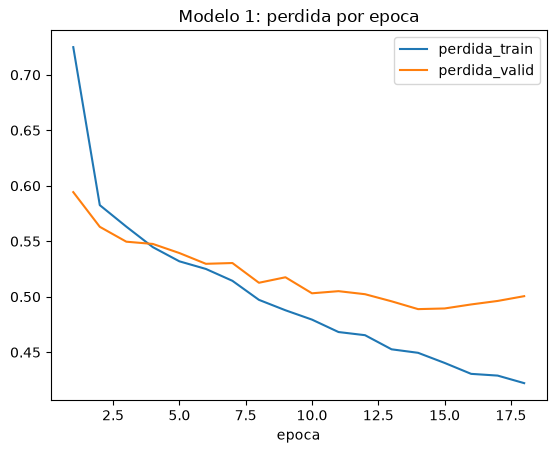

In [ ]:
def crear_mlp_01(dimension):
    return nn.Sequential(nn.Linear(dimension, 256), nn.ReLU(), nn.Dropout(0.20),
        nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.20), nn.Linear(128, 3))

def probabilidades_01(red, vectores):
    red.eval()
    partes = []
    with torch.inference_mode():
        for inicio in range(0, len(vectores), 512):
            partes.append(red(torch.tensor(vectores[inicio:inicio + 512], dtype=torch.float32)).softmax(1).numpy())
    return np.concatenate(partes)

def ajustar_mlp_01(vectores, etiquetas, epocas, validacion=None):
    torch.manual_seed(RANDOM_STATE)
    generador = torch.Generator().manual_seed(RANDOM_STATE)
    red = crear_mlp_01(vectores.shape[1])
    optimizador = torch.optim.AdamW(red.parameters(), lr=configuracion_01['lr'],
        weight_decay=configuracion_01['weight_decay'])
    perdida = nn.CrossEntropyLoss()
    lotes = DataLoader(TensorDataset(torch.tensor(vectores), etiquetas),
        batch_size=configuracion_01['batch_size'], shuffle=True, generator=generador, num_workers=0)
    historial, mejor_perdida, mejor_estado, mejor_epoca, sin_mejora = [], float('inf'), None, 0, 0
    for epoca in range(1, epocas + 1):
        red.train()
        suma, total = 0.0, 0
        for x_lote, y_lote in lotes:
            optimizador.zero_grad(set_to_none=True)
            error = perdida(red(x_lote), y_lote)
            error.backward()
            optimizador.step()
            suma += error.item() * len(y_lote)
            total += len(y_lote)
        fila = {'epoca': epoca, 'perdida_train': suma / total}
        if validacion is not None:
            x_v, y_v = validacion
            red.eval()
            with torch.inference_mode():
                logits = red(torch.tensor(x_v))
                error_v = perdida(logits, y_v).item()
            pred = logits.argmax(1).numpy()
            fila.update(perdida_valid=error_v, accuracy_valid=accuracy_score(y_v.numpy(), pred),
                f1_macro_valid=f1_score(y_v.numpy(), pred, average='macro', zero_division=0))
            if error_v < mejor_perdida - 0.0001:
                mejor_perdida, mejor_estado, mejor_epoca, sin_mejora = error_v, copy.deepcopy(red.state_dict()), epoca, 0
            else:
                sin_mejora += 1
        historial.append(fila)
        print(fila, flush=True)
        if validacion is not None and sin_mejora >= configuracion_01['patience']:
            break
    if validacion is not None:
        red.load_state_dict(mejor_estado)
    else:
        mejor_epoca = epocas
    return red.eval(), pd.DataFrame(historial), mejor_epoca

mlp_validacion_01, historial_01, mejor_epoca_01 = ajustar_mlp_01(
    embeddings_01[mascara_train_01], y_numerica_01[mascara_train_01],
    configuracion_01['max_epochs'],
    validacion=(embeddings_01[mascara_valid_01], y_numerica_01[mascara_valid_01]))
display(historial_01)
print('Epoca seleccionada por perdida:', mejor_epoca_01)
historial_01.set_index('epoca')[['perdida_train', 'perdida_valid']].plot(title='Modelo 1: perdida por epoca')
plt.show()


### Evaluación por clase e idioma estimado

Reportamos las métricas de la MLP en su mejor época. Los idiomas se toman del archivo de particiones y no son anotaciones oficiales. Grupos pequeños producen cifras inestables; informamos su tamaño. Los casos mixtos mal detectados siguen siendo una limitación. No utilizamos etiquetas de eval.


Modelo 1, validacion: {'accuracy': 0.722697288052773, 'f1_macro': 0.7378127057387555}
              precision    recall  f1-score   support

    negativo     0.6746    0.4973    0.5725      1476
     neutral     0.9628    0.9714    0.9671      1120
    positivo     0.6059    0.7589    0.6738      1497

    accuracy                         0.7227      4093
   macro avg     0.7478    0.7425    0.7378      4093
weighted avg     0.7283    0.7227    0.7175      4093



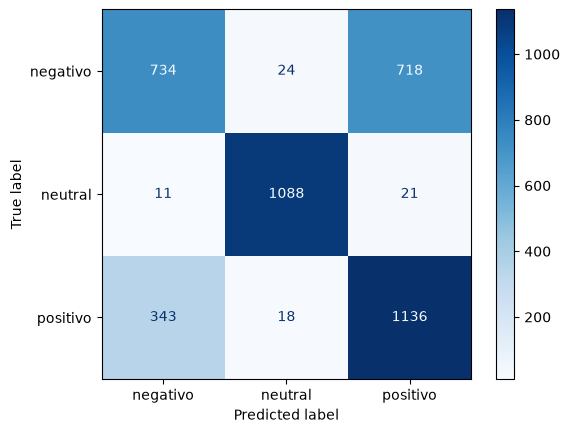

,ejemplos,accuracy,f1_macro
idioma,,,
en,470,0.776596,0.777027
es,2700,0.705556,0.724478
es_en_probable,22,0.545455,0.361111
fr,414,0.746377,0.759229
incierto,10,1.000000,1.000000
otra_mezcla_probable,15,0.733333,0.682540
pt,462,0.748918,0.758281


,id,text,label,prediccion,idioma_estimado
12,12,Un petit commentaire vite fait. L'ordinateur m'est arrivé en quatre jours au bureau où je l'utilise du lundi au vendredi. Je n'ai pas arrêté d'avoir des soucis avec le ventilat...,negativo,positivo,fr
52,52,"Se lo compre a un familiar hace un par de meses, nos llego en tres dias a la casa. La resistencia al agua termino siendo de mala calidad sin exagerar, la verdad. De resto lo he...",positivo,negativo,es
60,60,"Comprei esses fones sem fio mês passado pra usar no metrô indo pro trabalho, e minha filha também pega pra estudar. A bateria aguenta a semana toda, sério. Não diria que o som ...",positivo,negativo,pt
68,68,"Lo compré hace un mes para la oficina y lo tengo funcionando sin parar desde que llegó. Viene en color verde oscuro, tal cual lo pedí, y la caja llegó bien cerrada. La autonomí...",positivo,negativo,es
71,71,"Me llegó este teclado el martes por la tarde, dos días después de pedirlo, y lo vengo usando en la computadora de mi escritorio. Usa una pila recargable y la verdad sea dicha, ...",negativo,positivo,es
83,83,"Me llegó el procesador el jueves por la mañana, en su caja sellada, y lo instalé en la computadora de escritorio que uso para trabajo. El rendimiento funciona bastante mal. La ...",negativo,positivo,es


In [ ]:
probas_valid_01 = probabilidades_01(mlp_validacion_01, embeddings_01[mascara_valid_01])
pred_valid_01 = np.array(ETIQUETAS)[probas_valid_01.argmax(1)]
real_valid_01 = train.loc[mascara_valid_01, 'label'].to_numpy()
metricas_01 = dict(accuracy=float(accuracy_score(real_valid_01, pred_valid_01)),
    f1_macro=float(f1_score(real_valid_01, pred_valid_01, average='macro')))
print('Modelo 1, validacion:', metricas_01)
print(classification_report(real_valid_01, pred_valid_01, labels=ETIQUETAS, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(real_valid_01, pred_valid_01, labels=ETIQUETAS, cmap='Blues')
plt.show()
errores_01 = train.loc[mascara_valid_01, ['id', 'text', 'label']].copy()
errores_01['prediccion'] = pred_valid_01
errores_01['idioma_estimado'] = particiones_01.loc[mascara_valid_01, 'idioma_estimado'].to_numpy()
resumen_idiomas_01 = []
for idioma, datos in errores_01.groupby('idioma_estimado'):
    resumen_idiomas_01.append(dict(idioma=idioma, ejemplos=len(datos),
        accuracy=accuracy_score(datos['label'], datos['prediccion']),
        f1_macro=f1_score(datos['label'], datos['prediccion'], labels=ETIQUETAS, average='macro', zero_division=0)))
resumen_idiomas_01 = pd.DataFrame(resumen_idiomas_01).set_index('idioma')
display(resumen_idiomas_01)
with pd.option_context('display.max_colwidth', 180):
    display(errores_01.loc[errores_01['label'] != errores_01['prediccion']].head(6))


### Resultado del primer experimento

El modelo sin aumento obtuvo **72,27 % de accuracy** y **73,78 % de F1 macro** en las 4.093 reseñas de validación. Se seleccionó la época 14 por menor pérdida, aunque otra época tuvo un accuracy ligeramente superior: el criterio de selección ya estaba fijado y no lo cambiamos después.

Neutral tuvo recall 97,14 %, negativo 49,73 % y positivo 75,89 %. La dificultad principal sigue siendo positivo frente a negativo. En español se obtuvo 70,56 % de accuracy; inglés 77,66 %, portugués 74,89 % y francés 74,64 %. El grupo es/en probable obtuvo 54,55 %, pero solo tiene 22 ejemplos; estas cifras no demuestran generalización por idioma ni son comparables con anotaciones humanas oficiales. F1 macro por idioma considera las tres clases; si falta una clase se le asigna cero, por lo que hay que interpretar los subgrupos pequeños con cuidado.

La pérdida de entrenamiento siguió bajando después de la época 14 mientras la de validación empeoró: es una señal de sobreajuste y justifica recuperar el estado anterior. No afirmamos que regularización y parada temprana eliminen el problema. Los vectores congelados pueden perder información fina de orden, negación e ironía; como siguiente experimento podremos ajustar el encoder o comparar aumento, manteniendo la misma validación.

Este resultado es una referencia inicial, no evidencia de superar la línea base de Kaggle. No se realizó aumento ni un envío automático. La comparación obligatoria con y sin aumento sigue pendiente. El primer envío obtuvo 0.70923 público, registrado después de subir el CSV.


### Reentrenamiento final y primer CSV

Cerrada la evaluación, entrenamos una MLP nueva con todas las etiquetas de train durante el número de épocas seleccionado. No volvemos a calcular el score de validación con esta red final. Después inferimos eval con el encoder congelado y guardamos las respuestas. El primer intento es sin aumento: todavía falta la comparación obligatoria de aumento y los demás envíos.

Guardamos un único paquete PyTorch con pesos de la MLP, archivos completos del encoder/tokenizador, revisión, clases, configuración y versiones. No requiere descargar de nuevo el encoder para recargarlo. Se descarga desde GitHub Releases y se guarda junto al notebook. Ver MODELOS.md para los enlaces y las huellas de los paquetes.


In [ ]:
mlp_final_01, historial_final_01, _ = ajustar_mlp_01(
    embeddings_01, y_numerica_01, mejor_epoca_01)
embeddings_eval_01 = vectores_01(eval_df['text'].tolist(), huellas_datos['eval.csv'], 'eval')
probas_eval_01 = probabilidades_01(mlp_final_01, embeddings_eval_01)
submission_01 = pd.DataFrame({'id': eval_df['id'],
    'answer': np.array(ETIQUETAS)[probas_eval_01.argmax(1)]})
assert list(submission_01.columns) == list(plantilla.columns) == ['id', 'answer']
assert len(submission_01) == len(plantilla) == 6781
assert submission_01['id'].tolist() == plantilla['id'].tolist()
assert submission_01['id'].is_unique and not submission_01.isna().any().any()
assert submission_01['answer'].isin(ETIQUETAS).all()
Path('submissions').mkdir(exist_ok=True)
ruta_submission_01 = Path('submissions/submission_01_minilm_mlp_sin_aumento.csv')
submission_01.to_csv(ruta_submission_01, index=False)

encoder_01.to('cpu')
with tempfile.TemporaryDirectory() as temporal:
    encoder_01.save_pretrained(temporal, safe_serialization=True)
    archivos_encoder_01 = {str(p.relative_to(temporal)): p.read_bytes()
        for p in Path(temporal).rglob('*') if p.is_file()}
paquete_01 = dict(encoder_files=archivos_encoder_01, mlp_state=mlp_final_01.state_dict(),
    dimension=int(embeddings_01.shape[1]), etiquetas=ETIQUETAS,
    modelo_base=MODELO_BASE, revision=REVISION_BASE, max_tokens=MAX_TOKENS,
    configuracion=configuracion_01, epocas_finales=mejor_epoca_01,
    metricas_validacion=metricas_01, versiones=versiones_01,
    huellas_datos=huellas_datos, sha256_particiones=hashlib.sha256(Path('particiones.csv').read_bytes()).hexdigest(),
    semilla=RANDOM_STATE, aumento=False)
torch.save(paquete_01, 'modelo_01_multilingue.pt')
print('CSV:', ruta_submission_01.resolve())
print('Modelo guardado, MB:', round(Path('modelo_01_multilingue.pt').stat().st_size / 1024**2, 1))


{'epoca': 1, 'perdida_train': 0.7013824793363519}
{'epoca': 2, 'perdida_train': 0.5771182209390193}
{'epoca': 3, 'perdida_train': 0.5516551147455067}
{'epoca': 4, 'perdida_train': 0.5378148273371839}
{'epoca': 5, 'perdida_train': 0.5218958869703142}
{'epoca': 6, 'perdida_train': 0.5117025133406186}
{'epoca': 7, 'perdida_train': 0.5006905838819493}
{'epoca': 8, 'perdida_train': 0.4905585149661847}
{'epoca': 9, 'perdida_train': 0.481846112974529}
{'epoca': 10, 'perdida_train': 0.4693681926749662}
{'epoca': 11, 'perdida_train': 0.4637040997907515}
{'epoca': 12, 'perdida_train': 0.45540269117172216}
{'epoca': 13, 'perdida_train': 0.4478888748870571}
{'epoca': 14, 'perdida_train': 0.4389905527657828}
eval 256 / 6781
eval 2304 / 6781
eval 4352 / 6781
eval 6400 / 6781
eval : segundos de extraccion 32.1
CSV: /private/tmp/mlp2-modelo01/submissions/submission_01_minilm_mlp_sin_aumento.csv
Modelo guardado, MB: 692.7


### Comprobación de recarga sin Internet

Reconstruimos el encoder desde sus archivos empaquetados y la MLP desde sus pesos. La función sirve también en una sesión nueva después de ejecutar los imports y las definiciones crear_mlp_01 y probabilidades_01. Se compara toda la predicción de eval con el CSV usando los vectores del mismo encoder y se verifican además textos directamente con el encoder recargado. Solo se deben cargar modelos propios o de confianza.


In [ ]:
def cargar_modelo_01(ruta, dispositivo='cpu'):
    paquete = torch.load(ruta, map_location='cpu', weights_only=True)
    with tempfile.TemporaryDirectory() as temporal:
        raiz = Path(temporal).resolve()
        for nombre, contenido in paquete['encoder_files'].items():
            destino = (raiz / nombre).resolve()
            if raiz not in destino.parents:
                raise ValueError('Ruta invalida en el paquete')
            destino.parent.mkdir(parents=True, exist_ok=True)
            destino.write_bytes(contenido)
        encoder = SentenceTransformer(str(raiz), device=dispositivo, local_files_only=True, trust_remote_code=False)
    encoder.max_seq_length = paquete['max_tokens']
    red = crear_mlp_01(paquete['dimension'])
    red.load_state_dict(paquete['mlp_state'])
    return encoder.eval(), red.eval(), paquete

encoder_recargado_01, red_recargada_01, paquete_recargado_01 = cargar_modelo_01('modelo_01_multilingue.pt')
assert np.array_equal(probabilidades_01(red_recargada_01, embeddings_eval_01).argmax(1), probas_eval_01.argmax(1))
textos_prueba_01 = eval_df['text'].iloc[:12].tolist()
vectores_recargados_01 = encoder_recargado_01.encode(textos_prueba_01, batch_size=4,
    normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
assert np.allclose(vectores_recargados_01, embeddings_eval_01[:12], atol=0.0001)
assert np.array_equal(probabilidades_01(red_recargada_01, vectores_recargados_01).argmax(1), probas_eval_01[:12].argmax(1))
print('Recarga verificada: 6.781 respuestas iguales y 12 textos procesados desde el encoder empaquetado.')
print('El score publico se registra en la tabla de experimentos; no se calcula en esta celda.')


Recarga verificada: 6.781 respuestas iguales y 12 textos procesados desde el encoder empaquetado.
El score publico se registra en la tabla de experimentos; no se calcula en esta celda.


## Estado del primer submission

Se generó `submissions/submission_01_minilm_mlp_sin_aumento.csv` con 6.781 filas válidas y se guardó `modelo_01_multilingue.pt`. La recarga reprodujo las 6.781 etiquetas usando sus vectores y procesó directamente 12 textos con el encoder empaquetado. También se comprobó en otro proceso, en modo offline, una muestra de 18 textos distribuidos por `eval.csv`, sin reentrenar.

Tras subir manualmente el primer envío a Kaggle, obtuvo **Public Score: 0.70923**, consistente con el **72,27 %** de accuracy en validación local (`73,78 %` de F1 macro). Es una referencia inicial sin aumento; la cercanía entre cifras de conjuntos distintos no demuestra por sí sola que la partición estime perfectamente la generalización.

El paquete `modelo_01_multilingue.pt` ocupa aproximadamente 693 MB y se comparte en GitHub Releases; sigue excluido de los commits mediante `.gitignore`. En el siguiente experimento probamos si descongelar el encoder mediante *fine-tuning* supera la limitación de usar representaciones congeladas.

## Segundo intento: fine-tuning de MiniLM sin aumento

Mantenemos la base `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, revisión `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`. El encoder ahora es entrenable y se combina con mean pooling enmascarado, dropout 0,20 y una cabeza lineal de tres salidas.

La comparación mantiene la partición de 16.373/4.093 y no usa aumento. También cambian la cabeza (antes MLP) y la normalización de la representación (antes vectores normalizados). Por eso medimos el efecto de la nueva configuración completa, no aislamos causalmente el descongelamiento. Una ablación futura debería mantener cabeza, normalización y protocolo iguales para medir solo ese factor.

Usamos AdamW con tasas 3e-5 en el encoder y 1e-4 en la cabeza, weight decay 0,01, warmup 10 %, recorte de gradiente 1,0 y lotes efectivos de hasta 32. La acumulación suma pérdidas y divide gradientes entre los ejemplos realmente acumulados, incluidos los lotes incompletos.

El calendario conserva un horizonte de seis épocas tanto en validación como en el ajuste final. Se ejecutan hasta seis en desarrollo, con paciencia dos y recuperación de la menor pérdida; después se ejecuta solamente la cantidad elegida con todo train, sin comprimir el calendario a ese número. Las actualizaciones por época varían con el tamaño del conjunto. Las métricas de validación no son una evaluación independiente del modelo reentrenado con todo train.

Se corrigió una implementación anterior que obtuvo 88,59 % local. Sus archivos originales se conservaron como respaldo; ese resultado no se atribuye automáticamente al código corregido. Los resultados siguientes corresponden a su nueva ejecución.


In [ ]:
import gc
from functools import partial
from torch.utils.data import Dataset
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from huggingface_hub import snapshot_download

os.environ['HF_HUB_DISABLE_XET'] = '1'
dispositivo_02 = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
configuracion_02 = dict(
    lr_encoder=3e-5, lr_head=1e-4, weight_decay=0.01, warmup_ratio=0.10,
    max_grad_norm=1.0, dropout=0.20, batch_size=16, grad_accum=2,
    eval_batch_size=64, max_epochs=6, patience=2,
)
versiones_02 = {nombre: version(nombre) for nombre in
    ['torch', 'transformers', 'sentence-transformers', 'numpy', 'pandas', 'scikit-learn']}
versiones_02['Python'] = platform.python_version()
print('Dispositivo Modelo 2:', dispositivo_02)
print('Configuracion Modelo 2:', configuracion_02)
display(pd.Series(versiones_02, name='Version'))

ruta_base_02 = snapshot_download(MODELO_BASE, revision=REVISION_BASE, local_files_only=False)
tokenizador_02 = AutoTokenizer.from_pretrained(
    ruta_base_02, local_files_only=False, trust_remote_code=False)
ids_train_02 = tokenizador_02(train['text'].tolist(), truncation=True,
    max_length=MAX_TOKENS, padding=False)['input_ids']
ids_eval_02 = tokenizador_02(eval_df['text'].tolist(), truncation=True,
    max_length=MAX_TOKENS, padding=False)['input_ids']
print('Max tokens train:', max(map(len, ids_train_02)), '| Max tokens eval:', max(map(len, ids_eval_02)))

class DatasetResenas02(Dataset):
    def __init__(self, secuencias, etiquetas=None):
        if etiquetas is not None and len(secuencias) != len(etiquetas):
            raise ValueError('Debe haber una etiqueta por secuencia')
        self.secuencias = secuencias
        self.etiquetas = etiquetas

    def __len__(self):
        return len(self.secuencias)

    def __getitem__(self, idx):
        item = {'input_ids': self.secuencias[idx]}
        if self.etiquetas is not None:
            item['label'] = int(self.etiquetas[idx])
        return item

def collate_02(batch, *, pad_token_id, max_tokens):
    max_raw = max(len(x['input_ids']) for x in batch)
    max_len = min(max_tokens, ((max_raw + 31) // 32) * 32)
    input_ids = torch.full((len(batch), max_len), pad_token_id, dtype=torch.long)
    attention_mask = torch.zeros((len(batch), max_len), dtype=torch.long)
    for i, x in enumerate(batch):
        largo = min(len(x['input_ids']), max_len)
        input_ids[i, :largo] = torch.tensor(x['input_ids'][:largo], dtype=torch.long)
        attention_mask[i, :largo] = 1
    salida = {'input_ids': input_ids, 'attention_mask': attention_mask}
    if 'label' in batch[0]:
        salida['labels'] = torch.tensor([x['label'] for x in batch], dtype=torch.long)
    return salida

class ClasificadorMiniLM02(nn.Module):
    def __init__(self, encoder, dropout=0.20, num_clases=3, max_tokens=256):
        super().__init__()
        self.encoder = encoder
        self.max_tokens = max_tokens
        self.dropout = nn.Dropout(dropout)
        self.cabeza = nn.Linear(encoder.config.hidden_size, num_clases)

    def forward(self, input_ids, attention_mask):
        salida = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        mascara = attention_mask.unsqueeze(-1).float()
        agregado = (salida.last_hidden_state * mascara).sum(1) / mascara.sum(1).clamp(min=1e-9)
        return self.cabeza(self.dropout(agregado))

def predecir_probas_02(modelo, secuencias, tokenizador, batch_size=64, etiquetas=None):
    if not len(secuencias):
        raise ValueError('Se requiere al menos una secuencia')
    dispositivo = next(modelo.parameters()).device
    pad_id = tokenizador.pad_token_id if tokenizador.pad_token_id is not None else 0
    lotes = DataLoader(DatasetResenas02(secuencias, etiquetas), batch_size=batch_size,
        shuffle=False, collate_fn=partial(collate_02, pad_token_id=pad_id,
            max_tokens=modelo.max_tokens), num_workers=0)
    modelo.eval()
    perdida_fn = nn.CrossEntropyLoss(reduction='sum')
    partes, perdidas, total = [], [], 0
    with torch.inference_mode():
        for lote in lotes:
            logits = modelo(lote['input_ids'].to(dispositivo), lote['attention_mask'].to(dispositivo))
            if 'labels' in lote:
                perdidas.append(perdida_fn(logits, lote['labels'].to(dispositivo)).detach())
                total += len(lote['labels'])
            partes.append(logits.softmax(1))
    probabilidades = torch.cat(partes).cpu().numpy()
    perdida = (torch.stack(perdidas).cpu().double().sum().item() / total) if total else None
    return probabilidades, perdida

def normalizar_gradientes_02(modelo, muestras):
    if muestras <= 0:
        raise ValueError('No hay ejemplos acumulados')
    for parametro in modelo.parameters():
        if parametro.grad is not None:
            parametro.grad.div_(muestras)

def crear_planificador_02(optimizador, pasos_por_epoca, horizonte_epocas, warmup_ratio):
    total = pasos_por_epoca * horizonte_epocas
    return get_linear_schedule_with_warmup(optimizador,
        num_warmup_steps=int(total * warmup_ratio), num_training_steps=total)

def ajustar_finetuning_02(secuencias_tr, y_tr, epocas, validacion=None, *, horizonte_epocas=None, secuencias_aumentadas=None, prob_aumento=0.0, cada_lotes=250, configuracion=None):
    cfg = configuracion_02 if configuracion is None else configuracion
    horizonte = cfg['max_epochs'] if horizonte_epocas is None else horizonte_epocas
    if not 0 < epocas <= horizonte:
        raise ValueError('Las epocas ejecutadas deben estar entre 1 y el horizonte del calendario')
    torch.manual_seed(RANDOM_STATE)
    generador = torch.Generator().manual_seed(RANDOM_STATE)
    encoder = AutoModel.from_pretrained(ruta_base_02, local_files_only=False, trust_remote_code=False)
    modelo = ClasificadorMiniLM02(encoder, dropout=cfg['dropout'],
        max_tokens=MAX_TOKENS).to(dispositivo_02)
    sin_decay = ('bias', 'LayerNorm.weight', 'LayerNorm.bias')
    grupos = [
        {'params': [p for n, p in modelo.encoder.named_parameters() if not any(k in n for k in sin_decay)],
         'lr': cfg['lr_encoder'], 'weight_decay': cfg['weight_decay']},
        {'params': [p for n, p in modelo.encoder.named_parameters() if any(k in n for k in sin_decay)],
         'lr': cfg['lr_encoder'], 'weight_decay': 0.0},
        {'params': list(modelo.cabeza.parameters()), 'lr': cfg['lr_head'],
         'weight_decay': cfg['weight_decay']},
    ]
    optimizador = torch.optim.AdamW(grupos)
    pad_id = tokenizador_02.pad_token_id if tokenizador_02.pad_token_id is not None else 0
    con_aumento = secuencias_aumentadas is not None and prob_aumento > 0
    if not 0 <= prob_aumento <= 1:
        raise ValueError('Probabilidad de aumento inválida')
    datos_tr = (DatasetAumentado03(secuencias_tr, y_tr, secuencias_aumentadas,
        prob_aumento, RANDOM_STATE) if con_aumento else DatasetResenas02(secuencias_tr, y_tr))
    lotes_tr = DataLoader(datos_tr,
        batch_size=cfg['batch_size'], shuffle=True, generator=generador,
        collate_fn=partial(collate_02, pad_token_id=pad_id, max_tokens=MAX_TOKENS), num_workers=0)
    grad_accum = cfg['grad_accum']
    pasos_por_epoca = (len(lotes_tr) + grad_accum - 1) // grad_accum
    planificador = crear_planificador_02(optimizador, pasos_por_epoca, horizonte,
        cfg['warmup_ratio'])
    perdida_fn = nn.CrossEntropyLoss(reduction='sum')
    historial, mejor_perdida, mejor_estado, mejor_epoca, sin_mejora = [], float('inf'), None, 0, 0

    for epoca in range(1, epocas + 1):
        t0 = time.perf_counter()
        modelo.train()
        if con_aumento:
            datos_tr.fijar_epoca(epoca)
        perdidas_lotes, total, muestras_acumuladas = [], 0, 0
        optimizador.zero_grad(set_to_none=True)
        for paso, lote in enumerate(lotes_tr, 1):
            inp, mask = lote['input_ids'].to(dispositivo_02), lote['attention_mask'].to(dispositivo_02)
            etq = lote['labels'].to(dispositivo_02)
            error = perdida_fn(modelo(inp, mask), etq)
            error.backward()
            perdidas_lotes.append(error.detach())
            total += len(etq)
            muestras_acumuladas += len(etq)
            if paso % grad_accum == 0 or paso == len(lotes_tr):
                # El ultimo grupo puede tener menos de 32 ejemplos: todos deben pesar igual.
                normalizar_gradientes_02(modelo, muestras_acumuladas)
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), cfg['max_grad_norm'])
                optimizador.step()
                planificador.step()
                optimizador.zero_grad(set_to_none=True)
                muestras_acumuladas = 0
            if paso % cada_lotes == 0:
                print(f'Epoca {epoca}: lote {paso}/{len(lotes_tr)}', flush=True)
            if dispositivo_02 == 'mps' and paso % 50 == 0:
                torch.mps.empty_cache()
        if dispositivo_02 == 'mps':
            torch.mps.empty_cache()
        fila = {'epoca': epoca, 'perdida_train': torch.stack(perdidas_lotes).cpu().double().sum().item() / total,
            'segundos': round(time.perf_counter() - t0, 1),
            'horizonte_epocas': horizonte, 'pasos_por_epoca': pasos_por_epoca}
        if con_aumento:
            fila.update(ejemplos_aumentados=int(datos_tr.usar_variante.sum()),
                ejemplos_originales=int(total - datos_tr.usar_variante.sum()))
        if validacion is not None:
            sec_v, y_v = validacion
            probas_v, error_v = predecir_probas_02(modelo, sec_v, tokenizador_02,
                batch_size=cfg['eval_batch_size'], etiquetas=y_v)
            fila.update(perdida_valid=error_v, accuracy_valid=accuracy_score(y_v.numpy(), probas_v.argmax(1)),
                f1_macro_valid=f1_score(y_v.numpy(), probas_v.argmax(1), average='macro', zero_division=0))
            if error_v < mejor_perdida - 0.0005:
                mejor_perdida, mejor_epoca, sin_mejora = error_v, epoca, 0
                mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
        historial.append(fila)
        print(fila, flush=True)
        if validacion is not None and sin_mejora >= cfg['patience']:
            break
    if validacion is not None:
        modelo.load_state_dict(mejor_estado)
    else:
        mejor_epoca = epocas
    return modelo.eval(), pd.DataFrame(historial), mejor_epoca

def cargar_modelo_02(ruta, dispositivo='cpu'):
    paquete = torch.load(ruta, map_location='cpu', weights_only=True)
    with tempfile.TemporaryDirectory() as temporal:
        raiz = Path(temporal).resolve()
        for nombre, contenido in paquete['encoder_files'].items():
            destino = (raiz / nombre).resolve()
            if raiz not in destino.parents:
                raise ValueError('Ruta invalida en el paquete')
            destino.parent.mkdir(parents=True, exist_ok=True)
            destino.write_bytes(contenido)
        tok = AutoTokenizer.from_pretrained(str(raiz), local_files_only=True, trust_remote_code=False)
        enc = AutoModel.from_pretrained(str(raiz), local_files_only=True, trust_remote_code=False)
    modelo = ClasificadorMiniLM02(enc, dropout=paquete['configuracion']['dropout'],
        num_clases=len(paquete['etiquetas']), max_tokens=paquete['max_tokens'])
    modelo.cabeza.load_state_dict(paquete['cabeza_state'])
    return tok, modelo.to(dispositivo).eval(), paquete



Dispositivo Modelo 2: mps
Configuracion Modelo 2: {'lr_encoder': 3e-05, 'lr_head': 0.0001, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0, 'dropout': 0.2, 'batch_size': 16, 'grad_accum': 2, 'eval_batch_size': 64, 'max_epochs': 6, 'patience': 2}


torch                      2.9.1
transformers              4.57.3
sentence-transformers      5.1.2
numpy                      2.5.5
pandas                     3.1.1
scikit-learn               1.9.1
Python                   3.12.13
Name: Version, dtype: str

Max tokens train: 176 | Max tokens eval: 166


### Entrenar la referencia sin aumento

Esta celda ejecuta el ajuste del modelo 2; sus definiciones anteriores se pueden reutilizar sin repetirlo.


Epoca 1: lote 250/1024
Epoca 1: lote 500/1024
Epoca 1: lote 750/1024
Epoca 1: lote 1000/1024
{'epoca': 1, 'perdida_train': 0.5219501102661624, 'segundos': 446.2, 'horizonte_epocas': 6, 'pasos_por_epoca': 512, 'perdida_valid': 0.2775536396670627, 'accuracy_valid': 0.8602492059613975, 'f1_macro_valid': 0.8702110460039396}
Epoca 2: lote 250/1024
Epoca 2: lote 500/1024
Epoca 2: lote 750/1024
Epoca 2: lote 1000/1024
{'epoca': 2, 'perdida_train': 0.23579120146963764, 'segundos': 482.5, 'horizonte_epocas': 6, 'pasos_por_epoca': 512, 'perdida_valid': 0.23140191903709637, 'accuracy_valid': 0.8876129978011239, 'f1_macro_valid': 0.8962160823529922}
Epoca 3: lote 250/1024
Epoca 3: lote 500/1024
Epoca 3: lote 750/1024
Epoca 3: lote 1000/1024
{'epoca': 3, 'perdida_train': 0.16910495071832365, 'segundos': 499.2, 'horizonte_epocas': 6, 'pasos_por_epoca': 512, 'perdida_valid': 0.2570034864040275, 'accuracy_valid': 0.8922550696310775, 'f1_macro_valid': 0.9007898846900493}
Epoca 4: lote 250/1024
Epoca 4:

,epoca,perdida_train,segundos,horizonte_epocas,pasos_por_epoca,perdida_valid,accuracy_valid,f1_macro_valid
0,1,0.521950,446.2,6,512,0.277554,0.860249,0.870211
1,2,0.235791,482.5,6,512,0.231402,0.887613,0.896216
2,3,0.169105,499.2,6,512,0.257003,0.892255,0.900790
3,4,0.126127,526.7,6,512,0.293881,0.888346,0.897110


Se detuvo en la epoca: 4 | Epoca recuperada: 2


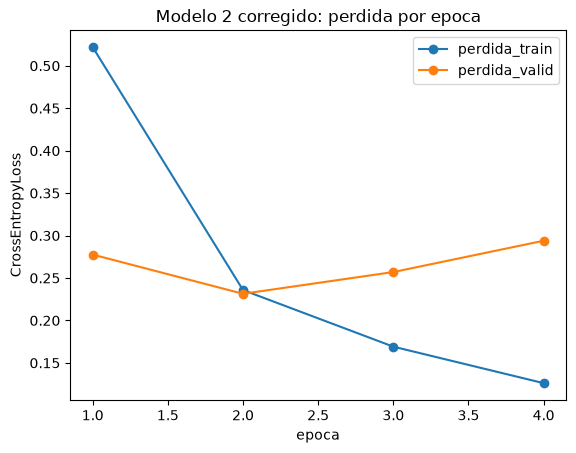

In [ ]:
sec_train_02 = [ids_train_02[i] for i in np.where(mascara_train_01)[0]]
sec_valid_02 = [ids_train_02[i] for i in np.where(mascara_valid_01)[0]]
y_train_02 = y_numerica_01[torch.from_numpy(mascara_train_01.copy())]
y_valid_02 = y_numerica_01[torch.from_numpy(mascara_valid_01.copy())]
modelo_valid_02, historial_02, mejor_epoca_02 = ajustar_finetuning_02(
    sec_train_02, y_train_02, configuracion_02['max_epochs'], validacion=(sec_valid_02, y_valid_02),
    horizonte_epocas=configuracion_02['max_epochs'])
display(historial_02)
print('Se detuvo en la epoca:', len(historial_02), '| Epoca recuperada:', mejor_epoca_02)
historial_02.set_index('epoca')[['perdida_train', 'perdida_valid']].plot(
    title='Modelo 2 corregido: perdida por epoca', marker='o')
plt.ylabel('CrossEntropyLoss')
plt.show()


### Evaluación por clase, brecha de generalización e idioma estimado

Evaluamos el estado recuperado por pérdida de validación y medimos también entrenamiento. La época seleccionada y la de detención se muestran en las salidas, no se fijan manualmente en el texto. La partición y las etiquetas no se modifican. Los idiomas son estimados; los grupos pequeños deben interpretarse con su cantidad de ejemplos.


Modelo 2, entrenamiento: 0.9237 | validacion: {'accuracy': 0.8876, 'f1_macro': 0.8962}
Diferencia vs Modelo 1 (validacion): accuracy +16.49 pp | f1_macro +15.84 pp
              precision    recall  f1-score   support

    negativo     0.8111    0.9045    0.8552      1476
     neutral     0.9964    0.9938    0.9951      1120
    positivo     0.8910    0.7916    0.8383      1497

    accuracy                         0.8876      4093
   macro avg     0.8995    0.8966    0.8962      4093
weighted avg     0.8910    0.8876    0.8873      4093



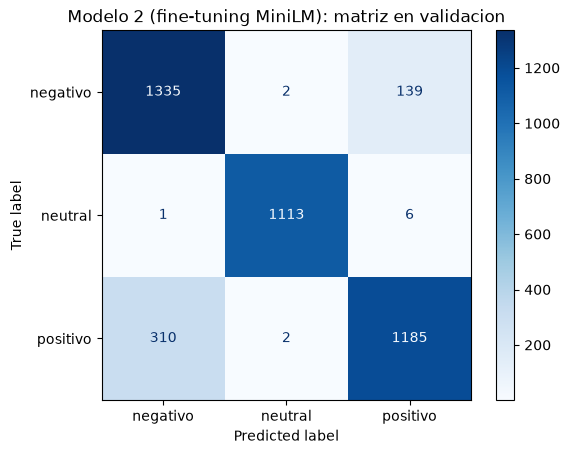

,ejemplos,accuracy_m1,accuracy,delta_acc_pp,f1_macro_m1,f1_macro,delta_f1_pp
idioma,,,,,,,
en,470,0.7766,0.8638,8.7234,0.7770,0.8663,8.9271
es,2700,0.7056,0.9070,20.1481,0.7245,0.9153,19.0850
es_en_probable,22,0.5455,0.8182,27.2727,0.3611,0.5455,18.4344
fr,414,0.7464,0.8188,7.2464,0.7592,0.8324,7.3181
incierto,10,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000
otra_mezcla_probable,15,0.7333,0.8667,13.3334,0.6825,0.8667,18.4127
pt,462,0.7489,0.8615,11.2554,0.7583,0.8677,10.9437


,id,text,label,prediccion,idioma_estimado
12,12,Un petit commentaire vite fait. L'ordinateur m'est arrivé en quatre jours au bureau où je l'utilise du lundi au vendredi. Je n'ai pas arrêté d'avoir des soucis avec le ventilat...,negativo,positivo,fr
83,83,"Me llegó el procesador el jueves por la mañana, en su caja sellada, y lo instalé en la computadora de escritorio que uso para trabajo. El rendimiento funciona bastante mal. La ...",negativo,positivo,es
168,168,"Ya con un tiempo de uso, lo llevo a todas partes, al trabajo y de viaje. El procesador se queda muy corto para lo que yo necesito, la verdad. Lo compré a comienzos de año y lle...",positivo,negativo,es
208,208,"Je l'ai acheté en ligne et il est arrivé chez moi en trois jours, aucun souci avec le colis. Je mettrais une étoile à l'écran, honnêtement. Au passage, j'ai été ravi des perfor...",negativo,positivo,fr
222,222,"Lo pedí a inicios de mes y llegó en unos ocho días, lo empecé a usar apenas la semana pasada. La construcción está por encima de la media, eso hay que decirlo. Lo tengo en el e...",negativo,positivo,es
400,400,"Lo compre a mediados de mayo y llego en tres dias a mi casa en Guadalajara, en caja cerrada. La verdad estoy arrepentido de haber comprado el acabado, la verdad que no me gusto...",positivo,negativo,es


In [17]:
probas_train_02, _ = predecir_probas_02(modelo_valid_02, sec_train_02, tokenizador_02, batch_size=configuracion_02['eval_batch_size'])
pred_train_02 = np.array(ETIQUETAS)[probas_train_02.argmax(1)]
real_train_02 = train.loc[mascara_train_01, 'label'].to_numpy()
acc_train_02 = float(accuracy_score(real_train_02, pred_train_02))

probas_valid_02, _ = predecir_probas_02(modelo_valid_02, sec_valid_02, tokenizador_02, batch_size=configuracion_02['eval_batch_size'])
pred_valid_02 = np.array(ETIQUETAS)[probas_valid_02.argmax(1)]
real_valid_02 = train.loc[mascara_valid_01, 'label'].to_numpy()
metricas_02 = dict(
    accuracy=float(accuracy_score(real_valid_02, pred_valid_02)),
    f1_macro=float(f1_score(real_valid_02, pred_valid_02, average='macro')),
    accuracy_train=acc_train_02,
)
print('Modelo 2, entrenamiento:', round(acc_train_02, 4), '| validacion:', {k: round(v, 4) for k, v in metricas_02.items() if k != 'accuracy_train'})
print('Diferencia vs Modelo 1 (validacion): accuracy', f"{(metricas_02['accuracy'] - metricas_01['accuracy'])*100:+.2f} pp | f1_macro {(metricas_02['f1_macro'] - metricas_01['f1_macro'])*100:+.2f} pp")
print(classification_report(real_valid_02, pred_valid_02, labels=ETIQUETAS, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(real_valid_02, pred_valid_02, labels=ETIQUETAS, cmap='Blues')
plt.title('Modelo 2 (fine-tuning MiniLM): matriz en validacion')
plt.show()

errores_02 = train.loc[mascara_valid_01, ['id', 'text', 'label']].copy()
errores_02['prediccion'] = pred_valid_02
errores_02['idioma_estimado'] = particiones_01.loc[mascara_valid_01, 'idioma_estimado'].to_numpy()
resumen_idiomas_02 = pd.DataFrame([
    dict(
        idioma=idioma,
        ejemplos=len(datos),
        accuracy=accuracy_score(datos['label'], datos['prediccion']),
        f1_macro=f1_score(datos['label'], datos['prediccion'], labels=ETIQUETAS, average='macro', zero_division=0),
    )
    for idioma, datos in errores_02.groupby('idioma_estimado')
]).set_index('idioma')

comparacion_idiomas_02 = resumen_idiomas_02.join(resumen_idiomas_01[['accuracy', 'f1_macro']], rsuffix='_m1')
comparacion_idiomas_02['delta_acc_pp'] = (comparacion_idiomas_02['accuracy'] - comparacion_idiomas_02['accuracy_m1']) * 100
comparacion_idiomas_02['delta_f1_pp'] = (comparacion_idiomas_02['f1_macro'] - comparacion_idiomas_02['f1_macro_m1']) * 100
comparacion_idiomas_02 = comparacion_idiomas_02[['ejemplos', 'accuracy_m1', 'accuracy', 'delta_acc_pp', 'f1_macro_m1', 'f1_macro', 'delta_f1_pp']]
display(comparacion_idiomas_02.round(4))

with pd.option_context('display.max_colwidth', 180):
    display(errores_02.loc[errores_02['label'] != errores_02['prediccion']].head(6))

del modelo_valid_02
gc.collect()
if dispositivo_02 == 'mps':
    torch.mps.empty_cache()

### Resultado del segundo experimento corregido

La configuración corregida obtuvo **88,76 % de accuracy** y **89,62 % de F1 macro**, frente al 72,27 % y 73,78 % del modelo 1, sobre las mismas 4.093 reseñas de validación. La diferencia fue **16,49 puntos de accuracy**. Esta comparación cambia encoder entrenable, cabeza y normalización: respalda la nueva configuración completa, no demuestra el efecto aislado de descongelar.

Se detuvo en la **época 4** y recuperó la **época 2**, con pérdida de validación 0.2314. La elección se hizo por pérdida, no escogiendo después el accuracy máximo. El accuracy en entrenamiento fue 92,37 %, una brecha de 3,60 puntos frente a validación; las curvas y esta brecha no prueban que se haya eliminado el sobreajuste.

Recall por clase: negativo 90,45 %, neutral 99,38 % y positivo 79,16 %. Revisamos errores por idioma con sus tamaños; el detector de idioma es aproximado y los grupos pequeños producen métricas inestables. Las diferencias entre idiomas no demuestran que la cantidad de datos sea su única causa.

La implementación anterior obtuvo 88,59 % local, pero usaba otra ponderación del último lote y comprimía el calendario del reentrenamiento final. Sus archivos se respaldaron antes de regenerar este CSV. No mezclamos métricas antiguas con artefactos corregidos. El CSV corregido obtuvo **0.85707 público (85,707 %)**, reportado por el equipo tras subirlo a Kaggle. Supera al primer envío (0.70923) en 14,78 puntos porcentuales y queda 3,05 puntos por debajo del accuracy local. Son conjuntos distintos: esta diferencia no demuestra por sí sola sobreajuste ni identifica su causa. La comparación obligatoria con aumento sigue pendiente.


### Reentrenamiento final y segundo CSV

Entrenamos un modelo nuevo con las 20.466 reseñas durante la cantidad de épocas elegida. Conservamos el horizonte de seis épocas para warmup/decaimiento; no lo acortamos al número de épocas ejecutadas. Este cambio corrige la política anterior de exportación. No reevaluamos sobre validación el modelo que ya aprendió con todas las etiquetas.

El paquete incluye versiones de Python y librerías, configuración, protocolo, horizonte y huellas. El CSV corregido reemplaza la versión local previa después de verificar la recarga. La versión anterior queda respaldada fuera del repositorio. Generar el CSV no equivale a subirlo a Kaggle.


In [18]:
modelo_final_02, historial_final_02, _ = ajustar_finetuning_02(
    ids_train_02, y_numerica_01, mejor_epoca_02, horizonte_epocas=configuracion_02['max_epochs']
)
probas_eval_02, _ = predecir_probas_02(
    modelo_final_02, ids_eval_02, tokenizador_02, batch_size=configuracion_02['eval_batch_size']
)
submission_02 = pd.DataFrame({
    'id': eval_df['id'],
    'answer': np.array(ETIQUETAS)[probas_eval_02.argmax(1)],
})
assert list(submission_02.columns) == list(plantilla.columns) == ['id', 'answer']
assert len(submission_02) == len(plantilla) == 6781
assert submission_02['id'].tolist() == plantilla['id'].tolist()
assert submission_02['id'].is_unique and not submission_02.isna().any().any()
assert submission_02['answer'].isin(ETIQUETAS).all()
Path('submissions').mkdir(exist_ok=True)
ruta_submission_02 = Path('submissions/submission_02_minilm_finetuning_sin_aumento.csv')
submission_02.to_csv(ruta_submission_02, index=False)

modelo_final_02.to('cpu')
with tempfile.TemporaryDirectory() as temporal:
    modelo_final_02.encoder.save_pretrained(temporal, safe_serialization=True)
    tokenizador_02.save_pretrained(temporal)
    archivos_encoder_02 = {
        str(p.relative_to(temporal)): p.read_bytes()
        for p in Path(temporal).rglob('*') if p.is_file()
    }
paquete_02 = dict(
    encoder_files=archivos_encoder_02,
    cabeza_state={k: v.detach().cpu().clone() for k, v in modelo_final_02.cabeza.state_dict().items()},
    etiquetas=ETIQUETAS,
    modelo_base=MODELO_BASE,
    revision=REVISION_BASE,
    max_tokens=MAX_TOKENS,
    configuracion=configuracion_02,
    versiones=versiones_02,
    protocolo='corregido_20261118',
    horizonte_epocas=configuracion_02['max_epochs'],
    pasos_por_epoca_final=int(historial_final_02['pasos_por_epoca'].iloc[0]),
    epocas_finales=mejor_epoca_02,
    metricas_validacion=metricas_02,
    huellas_datos=huellas_datos,
    sha256_particiones=hashlib.sha256(Path('particiones.csv').read_bytes()).hexdigest(),
    semilla=RANDOM_STATE,
    aumento=False,
)
torch.save(paquete_02, 'modelo_02_finetuning.pt')
print('CSV:', ruta_submission_02.resolve())
print('Distribucion predicha:', submission_02['answer'].value_counts().to_dict())
print('Modelo guardado, MB:', round(Path('modelo_02_finetuning.pt').stat().st_size / 1024**2, 1))

Epoca 1: lote 250/1280
Epoca 1: lote 500/1280
Epoca 1: lote 750/1280
Epoca 1: lote 1000/1280
Epoca 1: lote 1250/1280
{'epoca': 1, 'perdida_train': 0.4997693186227753, 'segundos': 611.5, 'horizonte_epocas': 6, 'pasos_por_epoca': 640}
Epoca 2: lote 250/1280
Epoca 2: lote 500/1280
Epoca 2: lote 750/1280
Epoca 2: lote 1000/1280
Epoca 2: lote 1250/1280
{'epoca': 2, 'perdida_train': 0.22016379657648974, 'segundos': 866.7, 'horizonte_epocas': 6, 'pasos_por_epoca': 640}
CSV: /private/tmp/mlp2-correccion02/submissions/submission_02_minilm_finetuning_sin_aumento.csv
Distribucion predicha: {'positivo': 3280, 'negativo': 2213, 'neutral': 1288}
Modelo guardado, MB: 692.3


### Comprobación de recarga sin Internet

El tokenizador y el encoder se reconstruyen desde el paquete, sin descargar archivos. La función de inferencia recibe el tokenizador y deduce el dispositivo de los pesos: cargar en CPU ya no depende del dispositivo global de entrenamiento. Se verifican las 6.781 respuestas contra el CSV. Una prueba adicional en un proceso independiente comprueba la llamada por defecto en CPU y una muestra de textos, sin ejecutar entrenamiento ni preparar globals del experimento.


In [19]:
tok_rec_02, mod_rec_02, paq_rec_02 = cargar_modelo_02('modelo_02_finetuning.pt', dispositivo=dispositivo_02)
ids_eval_rec_02 = tok_rec_02(eval_df['text'].tolist(), truncation=True,
    max_length=paq_rec_02['max_tokens'], padding=False)['input_ids']
probas_rec_02, _ = predecir_probas_02(mod_rec_02, ids_eval_rec_02, tok_rec_02,
    batch_size=configuracion_02['eval_batch_size'])
assert np.array_equal(probas_rec_02.argmax(1), probas_eval_02.argmax(1))
assert np.allclose(probas_rec_02, probas_eval_02, atol=1e-4)
assert submission_02['answer'].tolist() == np.array(paq_rec_02['etiquetas'])[probas_rec_02.argmax(1)].tolist()
print('Recarga verificada: 6.781 respuestas identicas al CSV y versiones incluidas en el paquete.')
print('La funcion de inferencia usa el dispositivo del modelo y el tokenizador recibido, sin globals.')
print('El score publico se registra en la tabla de experimentos; no se calcula en esta celda.')


Recarga verificada: 6.781 respuestas identicas al CSV y versiones incluidas en el paquete.
La funcion de inferencia usa el dispositivo del modelo y el tokenizador recibido, sin globals.
El score publico se registra en la tabla de experimentos; no se calcula en esta celda.


## Modelo 3: MiniLM con aumento de datos

Probamos si variar palabras de contexto ayuda a generalizar. Usamos la misma red, partición, semilla e hiperparámetros del modelo 2. El único cambio experimental es el aumento: una sustitución de una lista pequeña de equivalencias en español, inglés, portugués o francés, con probabilidad 0,30 por reseña elegible y época. No garantiza mejorar el score.

La idea se inspira en la sustitución de sinónimos de [EDA (Wei y Zou, 2019)](https://aclanthology.org/D19-1670/). Las reglas son propias; no usamos WordNet ni implementamos las cuatro operaciones de EDA. Por ejemplo, cambiamos “compré” por “adquirí”. Conservamos negaciones, conectores, números y el orden. La equivalencia puede fallar según el contexto: revisamos ejemplos y lo tratamos como una limitación.

El aumento se prepara solo con las 16.373 reseñas de entrenamiento. La validación se mantiene original y eval solo se usa para inferencia. Las variantes sustituyen temporalmente algunos originales; no duplicamos el conjunto ni añadimos actualizaciones por época. Las listas no se ajustaron después de ver los resultados del modelo 3.

Para retomar solo este intento tras reiniciar el kernel, ejecutar Imports, Carga, la configuración de redes del modelo 1, las definiciones del modelo 2 y estas celdas. No es necesario ejecutar los entrenamientos anteriores.


In [20]:
import re
REGLAS_AUMENTO_03 = {
    'es': {
        'compré': 'adquirí', 'compre': 'adquiri', 'comprado': 'adquirido',
        'comprada': 'adquirida', 'utilizo': 'uso', 'utilizar': 'usar',
        'utilizarlo': 'usarlo', 'utilizarla': 'usarla', 'por internet': 'en línea',
        'en internet': 'en línea', 'todos los días': 'a diario',
        'todos los dias': 'a diario', 'principalmente': 'sobre todo',
        'habitualmente': 'normalmente', 'necesitaba': 'requería',
        'aparato': 'dispositivo',
    },
    'en': {
        'bought': 'purchased', 'purchased': 'bought', 'every day': 'daily',
        'each day': 'daily', 'primarily': 'mainly', 'approximately': 'roughly',
        'using': 'utilizing', 'manufacturer': 'maker',
        'initially': 'at first', 'afterwards': 'afterward',
        'at the moment': 'currently',
    },
    'pt': {
        'comprei': 'adquiri', 'comprado': 'adquirido', 'comprada': 'adquirida',
        'pela internet': 'online', 'todos os dias': 'diariamente',
        'eu uso': 'eu utilizo', 'usar': 'utilizar', 'usando': 'utilizando',
        'precisava': 'necessitava', 'no começo': 'no início',
    },
    'fr': {
        'acheté': 'acquis', 'achetée': 'acquise', 'acheter': 'acquérir',
        'chaque jour': 'quotidiennement', 'tous les jours': 'chaque jour',
        'principalement': 'essentiellement', 'utilisé': 'employé',
        'utilise': 'emploie', 'appareil': 'dispositif',
        'en ligne': 'sur internet',
    },
}
PROB_AUMENTO_03 = 0.30
REENTRENAR_03 = False  # True solicita un ajuste nuevo; False reutiliza el paquete compatible.
patrones_aumento_03 = {
    idioma: [(re.compile(r'(?<!\w)' + re.escape(origen) + r'(?!\w)', re.I), origen, destino)
             for origen, destino in reglas.items()]
    for idioma, reglas in REGLAS_AUMENTO_03.items()
}
patron_protegido_03 = re.compile(
    r"(?<!\w)(?:no|not|never|without|neither|nor|n't|não|nunca|nem|sem|pas|jamais|"
    r"aucun|sans|rien|ni|nada|sin|pero|aunque|but|although|however|mas|porém|"
    r"embora|mais|pourtant|cependant)(?!\w)|n['’]|\d+(?:[.,]\d+)?", re.I)

def firma_protegida_03(texto):
    return tuple(m.group().casefold() for m in patron_protegido_03.finditer(texto))

def variante_03(texto, idioma, identificador, semilla=42):
    candidatos = []
    for patron, origen, destino in patrones_aumento_03.get(idioma, []):
        for coincidencia in patron.finditer(texto):
            candidatos.append((coincidencia.start(), coincidencia.end(), origen, destino))
    if not candidatos:
        return texto, 'sin_regla'
    valor = hashlib.sha256(f'{semilla}|{int(identificador)}|sinonimos_v1'.encode()).digest()
    inicio, fin, origen, destino = candidatos[int.from_bytes(valor[:8], 'big') % len(candidatos)]
    fragmento = texto[inicio:fin]
    if fragmento.isupper():
        destino = destino.upper()
    elif fragmento[0].isupper():
        destino = destino[0].upper() + destino[1:]
    nuevo = texto[:inicio] + destino + texto[fin:]
    assert firma_protegida_03(texto) == firma_protegida_03(nuevo)
    return nuevo, f'{idioma}: {origen} -> {destino}'

def preparar_aumentos_03(filas, idiomas, tokenizador, max_tokens=256, semilla=42):
    # Solo recibe la parte autorizada para entrenar; no consulta validación ni eval.
    if len(filas) != len(idiomas):
        raise ValueError('Debe haber un idioma por reseña')
    originales = filas['text'].tolist()
    variantes, reglas = [], []
    for fila, idioma in zip(filas.itertuples(), idiomas):
        texto, regla = variante_03(fila.text, idioma, fila.id, semilla)
        variantes.append(texto)
        reglas.append(regla)
    ids_originales = tokenizador(originales, truncation=True, max_length=max_tokens,
                                padding=False)['input_ids']
    ids_variantes = tokenizador(variantes, truncation=True, max_length=max_tokens,
                               padding=False)['input_ids']
    etiquetas_por_texto = {}
    for texto, etiqueta in zip(originales, filas['label']):
        etiquetas_por_texto.setdefault(texto.casefold().strip(), set()).add(etiqueta)
    motivos = []
    for i, (texto, etiqueta) in enumerate(zip(variantes, filas['label'])):
        motivo = 'aceptada'
        if reglas[i] == 'sin_regla':
            motivo = 'sin_regla'
        elif ids_variantes[i] == ids_originales[i]:
            motivo = 'sin_cambio_tokens'
        elif etiquetas_por_texto.get(texto.casefold().strip(), set()) - {etiqueta}:
            motivo = 'colision_con_otra_etiqueta'
        if motivo != 'aceptada':
            variantes[i] = originales[i]
            ids_variantes[i] = ids_originales[i]
        motivos.append(motivo)
    auditoria = filas[['id', 'label']].reset_index(drop=True).copy()
    auditoria['idioma_dominante'] = list(idiomas)
    auditoria['original'] = originales
    auditoria['variante'] = variantes
    auditoria['regla'] = reglas
    auditoria['control'] = motivos
    auditoria['aceptada'] = auditoria['control'].eq('aceptada')
    assert all(firma_protegida_03(a) == firma_protegida_03(b)
               for a, b in zip(originales, variantes))
    return ids_originales, ids_variantes, auditoria

class DatasetAumentado03(DatasetResenas02):
    def __init__(self, secuencias, etiquetas, variantes, probabilidad, semilla=42):
        super().__init__(secuencias, etiquetas)
        if len(variantes) != len(secuencias) or not 0 <= probabilidad <= 1:
            raise ValueError('Variantes o probabilidad inválidas')
        self.variantes = variantes
        self.probabilidad = probabilidad
        self.semilla = semilla
        self.elegibles = np.array([a != b for a, b in zip(secuencias, variantes)])
        self.usar_variante = np.zeros(len(self), dtype=bool)

    def fijar_epoca(self, epoca):
        # Este generador no altera la semilla de PyTorch ni el orden de los lotes.
        azar = np.random.default_rng(np.random.SeedSequence([self.semilla, epoca]))
        self.usar_variante = (azar.random(len(self)) < self.probabilidad) & self.elegibles

    def __getitem__(self, idx):
        item = super().__getitem__(idx)
        if self.usar_variante[idx]:
            item['input_ids'] = self.variantes[idx]
        return item


### Preparar y revisar las variantes

Rechazamos cambios que el tokenizador no vea y coincidencias con otra etiqueta dentro del entrenamiento. Mostramos cobertura por idioma y clase, y ejemplos antes/después. Los idiomas son estimados; las mezclas usan el idioma dominante. Estos controles reducen errores, pero no prueban equivalencia semántica en todos los casos.


In [21]:
# Para retomar solo este intento: Imports, Carga, configuración de redes,
# Definiciones del modelo 2 y las celdas del modelo 3. No ejecutar los fits anteriores.
import re
for nombre_temporal in ['modelo_final_02', 'mod_rec_02', 'paq_rec_02', 'paquete_02',
        'archivos_encoder_02', 'encoder_01', 'encoder_recargado_01', 'paquete_01',
        'archivos_encoder_01', 'paquete_recargado_01']:
    globals().pop(nombre_temporal, None)
gc.collect()
if dispositivo_02 == 'mps':
    torch.mps.empty_cache()
referencia_historica_02 = {'origen': 'Modelo 2 corregido, ejecución del 18 de noviembre de 2026', 'sha256_train': '23af8502589d7e7f36dcc3d82d7a8e69d7ba8df4b5f2ac8851ab210f0895002c', 'sha256_particiones': '6e6d9aad443cf22569aefa0e06609ad7ba64273963b3f3df83d79c4dde506401', 'metricas': {'accuracy': 0.8876129978011239, 'f1_macro': 0.8962160823529922, 'accuracy_train': 0.9236547975325231}, 'idiomas': [{'idioma': 'en', 'ejemplos': 470, 'accuracy': 0.8638297872340426, 'f1_macro': 0.8662980935429075}, {'idioma': 'es', 'ejemplos': 2700, 'accuracy': 0.9070370370370371, 'f1_macro': 0.9153275044956967}, {'idioma': 'es_en_probable', 'ejemplos': 22, 'accuracy': 0.8181818181818182, 'f1_macro': 0.5454545454545455}, {'idioma': 'fr', 'ejemplos': 414, 'accuracy': 0.8188405797101449, 'f1_macro': 0.8324098784519586}, {'idioma': 'incierto', 'ejemplos': 10, 'accuracy': 1.0, 'f1_macro': 1.0}, {'idioma': 'otra_mezcla_probable', 'ejemplos': 15, 'accuracy': 0.8666666666666667, 'f1_macro': 0.8666666666666667}, {'idioma': 'pt', 'ejemplos': 462, 'accuracy': 0.8614718614718615, 'f1_macro': 0.8677177549350765}], 'reporte': {'negativo': {'precision': 0.8110571081409478, 'recall': 0.9044715447154471, 'f1-score': 0.8552210121716848, 'support': 1476.0}, 'neutral': {'precision': 0.9964189794091316, 'recall': 0.99375, 'f1-score': 0.9950827000447027, 'support': 1120.0}, 'positivo': {'precision': 0.8909774436090225, 'recall': 0.7915831663326653, 'f1-score': 0.8383445348425893, 'support': 1497.0}, 'accuracy': 0.8876129978011239, 'macro avg': {'precision': 0.8994845103863675, 'recall': 0.8966015703493708, 'f1-score': 0.8962160823529922, 'support': 4093.0}, 'weighted avg': {'precision': 0.8910097194324391, 'recall': 0.8876129978011239, 'f1-score': 0.8873199625396605, 'support': 4093.0}}}
assert huellas_datos['train.csv'] == referencia_historica_02['sha256_train']
assert hashlib.sha256(Path('particiones.csv').read_bytes()).hexdigest() == referencia_historica_02['sha256_particiones']
configuracion_03 = copy.deepcopy(configuracion_02)
metricas_base_03 = dict(globals().get('metricas_02', referencia_historica_02['metricas']))
idiomas_base_03 = globals().get('resumen_idiomas_02',
    pd.DataFrame(referencia_historica_02['idiomas']).set_index('idioma')).copy()
print('Referencia:', 'modelo 2 de esta sesión' if 'metricas_02' in globals()
      else referencia_historica_02['origen'])
print('Configuración idéntica a modelo 2:', configuracion_03)
print('Probabilidad de variante por ejemplo elegible y época:', PROB_AUMENTO_03)
filas_desarrollo_03 = train.loc[mascara_train_01].copy()
assert set(filas_desarrollo_03['id']).isdisjoint(train.loc[mascara_valid_01, 'id'])
sec_train_03, variantes_train_03, auditoria_03 = preparar_aumentos_03(
    filas_desarrollo_03, particiones_01.loc[mascara_train_01, 'idioma_dominante'],
    tokenizador_02, MAX_TOKENS, RANDOM_STATE)
sec_valid_03 = [ids_train_02[i] for i in np.flatnonzero(mascara_valid_01)]
y_train_03 = y_numerica_01[torch.from_numpy(mascara_train_01.copy())]
y_valid_03 = y_numerica_01[torch.from_numpy(mascara_valid_01.copy())]
assert sec_train_03 == [ids_train_02[i] for i in np.flatnonzero(mascara_train_01)]
assert len(sec_train_03) == 16373 and len(sec_valid_03) == 4093
print('Controles de las variantes:')
display(auditoria_03['control'].value_counts().to_frame('Cantidad'))
cobertura_03 = auditoria_03.groupby('idioma_dominante')['aceptada'].agg(['size', 'sum', 'mean'])
display(cobertura_03.rename(columns={'size': 'Originales', 'sum': 'Con variante', 'mean': 'Proporción'}).round(4))
display(pd.crosstab(auditoria_03['label'], auditoria_03['aceptada']))
for idioma, filas in auditoria_03.loc[auditoria_03['aceptada']].groupby('idioma_dominante'):
    ejemplo = filas.iloc[0]
    print(f"\n{idioma} | id {ejemplo['id']} | {ejemplo['regla']}")
    print('Original:', ejemplo['original'])
    print('Variante:', ejemplo['variante'])


Referencia: Modelo 2 corregido, ejecución del 18 de noviembre de 2026
Configuración idéntica a modelo 2: {'lr_encoder': 3e-05, 'lr_head': 0.0001, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0, 'dropout': 0.2, 'batch_size': 16, 'grad_accum': 2, 'eval_batch_size': 64, 'max_epochs': 6, 'patience': 2}
Probabilidad de variante por ejemplo elegible y época: 0.3
Controles de las variantes:


,Cantidad
control,
aceptada,11853
sin_regla,4520


,Originales,Con variante,Proporción
idioma_dominante,,,
en,1890,1374,0.7270
es,10942,7863,0.7186
fr,1678,1204,0.7175
pt,1863,1412,0.7579


aceptada,False,True
label,,
negativo,1511,4394
neutral,1547,2932
positivo,1462,4527



en | id 19 | en: bought -> Purchased
Original: Bought this security camera for the driveway in March because packages kept disappearing. Honestly, the night vision is crystal clear, we caught a raccoon raiding the bins at 3am and could see every detail. My husband checks the app from work all the time now. The motion alerts are instant, never missed a thing, and setup took my son like ten minutes. Worth every penny, the picture quality really is that good.
Variante: Purchased this security camera for the driveway in March because packages kept disappearing. Honestly, the night vision is crystal clear, we caught a raccoon raiding the bins at 3am and could see every detail. My husband checks the app from work all the time now. The motion alerts are instant, never missed a thing, and setup took my son like ten minutes. Worth every penny, the picture quality really is that good.

es | id 0 | es: por internet -> en línea
Original: Lo pedí un martes por internet y llegó al tercer día, viene

### Entrenar o reutilizar el tercer modelo

Conservamos el protocolo de desarrollo: 512 actualizaciones por época, horizonte de seis épocas, paciencia dos y selección por pérdida. El aumento no añade actualizaciones. La pérdida de entrenamiento usa dropout y variantes; la comparación posterior de accuracy usa los textos originales y modo evaluación.

Para ahorrar tiempo, si ya existe un paquete compatible lo recargamos con `REENTRENAR_03 = False`. Comprobamos datos, partición, revisión, hiperparámetros y aumento. Para solicitar otro ajuste se cambia a `True`. Las instrucciones para ejecutar solo el modelo 3 evitan repetir los modelos anteriores.


Epoca 1: lote 100/1024
Epoca 1: lote 200/1024
Epoca 1: lote 300/1024
Epoca 1: lote 400/1024
Epoca 1: lote 500/1024
Epoca 1: lote 600/1024
Epoca 1: lote 700/1024
Epoca 1: lote 800/1024
Epoca 1: lote 900/1024
Epoca 1: lote 1000/1024
{'epoca': 1, 'perdida_train': 0.52518262360708, 'segundos': 133.2, 'horizonte_epocas': 6, 'pasos_por_epoca': 512, 'ejemplos_aumentados': 3633, 'ejemplos_originales': 12740, 'perdida_valid': 0.2594781076881899, 'accuracy_valid': 0.8668458343513316, 'f1_macro_valid': 0.8769113091654827}
Epoca 2: lote 100/1024
Epoca 2: lote 200/1024
Epoca 2: lote 300/1024
Epoca 2: lote 400/1024
Epoca 2: lote 500/1024
Epoca 2: lote 600/1024
Epoca 2: lote 700/1024
Epoca 2: lote 800/1024
Epoca 2: lote 900/1024
Epoca 2: lote 1000/1024
{'epoca': 2, 'perdida_train': 0.2336835451012299, 'segundos': 135.7, 'horizonte_epocas': 6, 'pasos_por_epoca': 512, 'ejemplos_aumentados': 3672, 'ejemplos_originales': 12701, 'perdida_valid': 0.22960609204897867, 'accuracy_valid': 0.8834595651111654, '

,epoca,perdida_train,segundos,horizonte_epocas,pasos_por_epoca,ejemplos_aumentados,ejemplos_originales,perdida_valid,accuracy_valid,f1_macro_valid
0,1,0.525183,133.2,6,512,3633,12740,0.259478,0.866846,0.876911
1,2,0.233684,135.7,6,512,3672,12701,0.229606,0.883460,0.892606
2,3,0.164912,135.9,6,512,3460,12913,0.250168,0.887857,0.896721
3,4,0.123516,136.3,6,512,3507,12866,0.319815,0.883460,0.892575


Épocas observadas: 4 | Época recuperada: 2


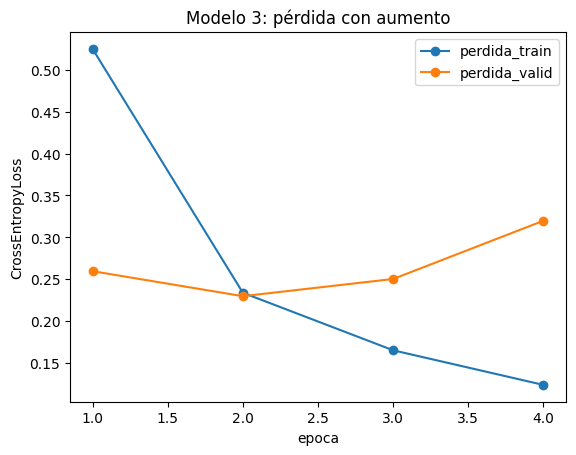

In [22]:
ruta_modelo_03 = Path('modelo_03_minilm_aumento.pt')
desde_cache_03 = ruta_modelo_03.exists() and not REENTRENAR_03
if desde_cache_03:
    tok_cache_03, modelo_valid_03, meta_cache_03 = cargar_modelo_02(
        ruta_modelo_03, dispositivo=dispositivo_02)
    assert meta_cache_03['huellas_datos'] == huellas_datos, 'Cambian los datos: revisar antes de reutilizar'
    assert meta_cache_03['sha256_particiones'] == referencia_historica_02['sha256_particiones']
    assert meta_cache_03['configuracion'] == configuracion_03
    assert meta_cache_03['revision'] == REVISION_BASE
    assert meta_cache_03['entrenado_con_todo_train'] is True
    assert meta_cache_03['ids_entrenamiento'] == train['id'].tolist()
    assert meta_cache_03['estrategia_aumento']['reglas'] == REGLAS_AUMENTO_03
    assert meta_cache_03['estrategia_aumento']['probabilidad'] == PROB_AUMENTO_03
    ids_cache_03 = tok_cache_03(train['text'].tolist(), truncation=True,
        max_length=MAX_TOKENS, padding=False)['input_ids']
    assert ids_cache_03 == ids_train_02
    historial_03 = pd.DataFrame(meta_cache_03['historial_validacion'])
    mejor_epoca_03 = int(meta_cache_03['epoca_seleccionada'])
    meta_cache_03.pop('encoder_files', None)
    print('Modelo 3 recuperado del paquete compatible; no se repite el entrenamiento.')
else:
    modelo_valid_03, historial_03, mejor_epoca_03 = ajustar_finetuning_02(
        sec_train_03, y_train_03, configuracion_03['max_epochs'],
        validacion=(sec_valid_03, y_valid_03),
        horizonte_epocas=configuracion_03['max_epochs'],
        secuencias_aumentadas=variantes_train_03, prob_aumento=PROB_AUMENTO_03, cada_lotes=100,
        configuracion=configuracion_03)
display(historial_03)
assert historial_03['pasos_por_epoca'].eq(512).all()
assert (historial_03['ejemplos_aumentados'] + historial_03['ejemplos_originales']).eq(16373).all()
print('Épocas observadas:', len(historial_03), '| Época recuperada:', mejor_epoca_03)
historial_03.set_index('epoca')[['perdida_train', 'perdida_valid']].plot(
    title='Modelo 3: pérdida con aumento', marker='o')
plt.ylabel('CrossEntropyLoss')
plt.show()


### Comparación y errores por idioma

Medimos ambos conjuntos con sus textos originales. Comparamos accuracy, F1 macro y la brecha de entrenamiento con la referencia sin aumento. Si el modelo 2 no se ejecutó en esta sesión, usamos sus resultados históricos guardados aquí y comprobamos las huellas de train y particiones.

Los grupos pequeños tienen métricas inestables y el idioma no es una anotación oficial. Una sola semilla y una validación reutilizada no permiten afirmar que una diferencia pequeña sea una mejora general garantizada. No se evalúa aquí el futuro modelo reentrenado con todas las etiquetas.


,accuracy,f1_macro,accuracy_train,perdida_valid,brecha_train_valid_pp
MiniLM sin aumento (2),0.8876,0.8962,0.9237,NaN,3.6042
MiniLM con aumento (3),0.8835,0.8926,0.9314,0.2296,4.7891


Cambio de accuracy: -0.415 pp
              precision    recall  f1-score   support

    negativo     0.8266    0.8625    0.8442      1476
     neutral     0.9947    0.9964    0.9955      1120
    positivo     0.8574    0.8196    0.8381      1497

    accuracy                         0.8835      4093
   macro avg     0.8929    0.8928    0.8926      4093
weighted avg     0.8839    0.8835    0.8834      4093



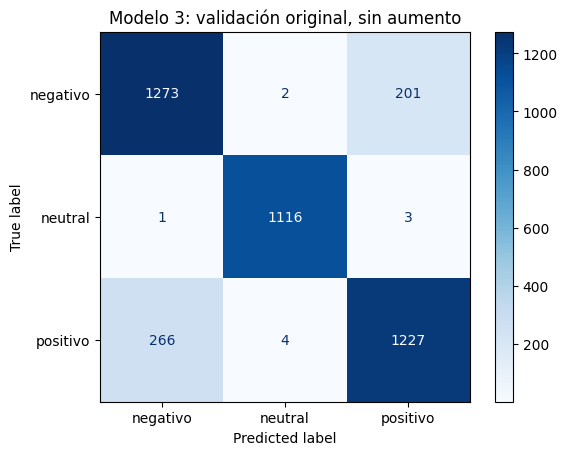

,ejemplos,accuracy_sin_aumento,f1_macro_sin_aumento,accuracy_con_aumento,f1_macro_con_aumento,delta_accuracy_pp,delta_f1_pp
idioma,,,,,,,
en,470,0.8638,0.8663,0.8617,0.8643,-0.2128,-0.1996
es,2700,0.9070,0.9153,0.9030,0.9118,-0.4074,-0.3487
es_en_probable,22,0.8182,0.5455,0.8182,0.5444,0.0000,-0.1010
fr,414,0.8188,0.8324,0.8019,0.8161,-1.6908,-1.6346
incierto,10,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
otra_mezcla_probable,15,0.8667,0.8667,0.8667,0.8667,0.0000,0.0000
pt,462,0.8615,0.8677,0.8658,0.8724,0.4329,0.4724


Errores de validación: 477

en: 65 errores. id=726; real=positivo; predicción=negativo
I bought this online because I urgently needed it and it arrived in three days. Wanted to note that. I was really annoyed with the size, honestly. By the way, the manufacturer's app surprised me in a good way. It's been sitting on my desk ever since.

es: 262 errores. id=83; real=negativo; predicción=positivo
Me llegó el procesador el jueves por la mañana, en su caja sellada, y lo instalé en la computadora de escritorio que uso para trabajo. El rendimiento funciona bastante mal. La compra me la recomendó un compa que ya llevaba tiempo con el mismo modelo. Aun así, volvería a comprar el procesador sin pensarlo. Cada quien que juzgue.

es_en_probable: 4 errores. id=1186; real=positivo; predicción=negativo
El teclado mecanico llego en dos dias, packaging impecable y los switches blue suenan super crisp, casi ASMR. Pero el cable viene rayado y el software de macros esta buggy, cada vez que assigno un key

In [23]:
if desde_cache_03 and meta_cache_03.get('entrenado_con_todo_train', False):
    guardadas_03 = pd.DataFrame(meta_cache_03['predicciones_validacion'])
    assert guardadas_03['id'].tolist() == train.loc[mascara_valid_01, 'id'].tolist()
    pred_valid_03 = guardadas_03['prediccion'].to_numpy()
    confianza_valid_03 = guardadas_03['confianza_prediccion'].to_numpy()
    real_valid_03 = train.loc[mascara_valid_01, 'label'].to_numpy()
    metricas_03 = dict(meta_cache_03['metricas_validacion'])
else:
    probas_train_03, _ = predecir_probas_02(modelo_valid_03, sec_train_03, tokenizador_02,
        batch_size=configuracion_03['eval_batch_size'])
    probas_valid_03, perdida_valid_03 = predecir_probas_02(modelo_valid_03, sec_valid_03, tokenizador_02,
        batch_size=configuracion_03['eval_batch_size'], etiquetas=y_valid_03)
    pred_valid_03 = np.array(ETIQUETAS)[probas_valid_03.argmax(1)]
    confianza_valid_03 = probas_valid_03.max(1)
    real_valid_03 = train.loc[mascara_valid_01, 'label'].to_numpy()
    metricas_03 = dict(accuracy=float(accuracy_score(real_valid_03, pred_valid_03)),
        f1_macro=float(f1_score(real_valid_03, pred_valid_03, labels=ETIQUETAS, average='macro')),
        accuracy_train=float(accuracy_score(y_train_03.numpy(), probas_train_03.argmax(1))),
        perdida_valid=float(perdida_valid_03))
comparacion_03 = pd.DataFrame([metricas_base_03, metricas_03],
    index=['MiniLM sin aumento (2)', 'MiniLM con aumento (3)'])
comparacion_03['brecha_train_valid_pp'] = 100 * (comparacion_03['accuracy_train'] - comparacion_03['accuracy'])
display(comparacion_03.round(4))
print('Cambio de accuracy:', round(100 * (metricas_03['accuracy'] - metricas_base_03['accuracy']), 3), 'pp')
print(classification_report(real_valid_03, pred_valid_03, labels=ETIQUETAS, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(real_valid_03, pred_valid_03, labels=ETIQUETAS, cmap='Blues')
plt.title('Modelo 3: validación original, sin aumento')
plt.show()
resultados_validacion_03 = train.loc[mascara_valid_01, ['id', 'text', 'label']].copy()
resultados_validacion_03['prediccion'] = pred_valid_03
resultados_validacion_03['idioma_estimado'] = particiones_01.loc[mascara_valid_01, 'idioma_estimado'].to_numpy()
resultados_validacion_03['confianza_prediccion'] = confianza_valid_03
resumen_idiomas_03 = pd.DataFrame([
    dict(idioma=idioma, ejemplos=len(filas),
         accuracy=float(accuracy_score(filas['label'], filas['prediccion'])),
         f1_macro=float(f1_score(filas['label'], filas['prediccion'], labels=ETIQUETAS,
                                 average='macro', zero_division=0)))
    for idioma, filas in resultados_validacion_03.groupby('idioma_estimado')
]).set_index('idioma')
comparacion_idiomas_03 = idiomas_base_03[['ejemplos', 'accuracy', 'f1_macro']].join(
    resumen_idiomas_03[['accuracy', 'f1_macro']], lsuffix='_sin_aumento', rsuffix='_con_aumento')
comparacion_idiomas_03['delta_accuracy_pp'] = 100 * (comparacion_idiomas_03['accuracy_con_aumento']
    - comparacion_idiomas_03['accuracy_sin_aumento'])
comparacion_idiomas_03['delta_f1_pp'] = 100 * (comparacion_idiomas_03['f1_macro_con_aumento']
    - comparacion_idiomas_03['f1_macro_sin_aumento'])
display(comparacion_idiomas_03.round(4))
fallos_03 = resultados_validacion_03.loc[resultados_validacion_03['label'] != resultados_validacion_03['prediccion']]
print('Errores de validación:', len(fallos_03))
for idioma, filas in fallos_03.groupby('idioma_estimado'):
    ejemplo = filas.iloc[0]
    print(f"\n{idioma}: {len(filas)} errores. id={ejemplo['id']}; real={ejemplo['label']}; predicción={ejemplo['prediccion']}")
    print(ejemplo['text'])
gc.collect()
if dispositivo_02 == 'mps':
    torch.mps.empty_cache()

### Resultado del tercer experimento

El tercer modelo (fine-tuning de MiniLM con sustitución léxica controlada, probabilidad `0,30` por reseña elegible y época) obtuvo **88,35 % de accuracy** (`0.8835`) y **89,26 % de F1 macro** (`0.8926`) sobre las 4.093 reseñas originales de validación, frente al **88,76 % de accuracy** y **89,62 % de F1 macro** del Modelo 2 sin aumento (**-0,415 puntos porcentuales** en accuracy y **-0,361 puntos** en F1 macro).

El ajuste de desarrollo se detuvo en la **época 4** por paciencia y recuperó la **época 2** por menor pérdida de validación (`0.2296`, ligeramente inferior al `0.2314` del Modelo 2). Al evaluar los pesos recuperados sobre las 16.373 reseñas originales de entrenamiento en modo evaluación, el accuracy fue **93,14 %**, lo que representa una brecha entrenamiento-validación de **4,79 puntos porcentuales** (frente a `3,60 puntos` sin aumento).

Por clase en validación, `neutral` alcanzó `99,47 %` de precisión y `99,64 %` de recall (`F1 = 99,55 %`); `negativo` obtuvo `82,66 %` de precisión y `86,25 %` de recall (`F1 = 84,42 %`); y `positivo` logró `85,74 %` de precisión y `81,96 %` de recall (`F1 = 83,81 %`). En comparación con el Modelo 2, el aumento incrementó el recall de `positivo` (`79,16 %` → `81,96 %`), pero redujo el recall de `negativo` (`90,45 %` → `86,25 %`).

Por idioma estimado (477 errores totales frente a 460 en el Modelo 2), portugués mejoró ligeramente (`86,15 %` → `86,58 %`, `+0,43 pp`, 62 errores), mientras que hubo ligeras caídas en inglés (`86,38 %` → `86,17 %`, `-0,21 pp`, 65 errores), español (`90,70 %` → `90,30 %`, `-0,41 pp`, 262 errores) y francés (`81,88 %` → `80,19 %`, `-1,69 pp`, 82 errores). Los grupos pequeños (`es_en_probable` con `81,82 %`, `otra_mezcla_probable` con `86,67 %` e `incierto` con `100,00 %`) mantuvieron el mismo accuracy. Esto confirma que la sustitución léxica conservadora no garantiza superar al fine-tuning sin aumento en toda partición; el score público queda pendiente de envío manual a Kaggle.

### Reentrenamiento final con todo train y tercer submission

Siguiendo el mismo protocolo del Modelo 2, realizamos un segundo ajuste final con todas las **20.466 reseñas de `train.csv`** (con aumento léxico controlado: `14.846` variantes aceptadas y `5.620` sin regla) durante `mejor_epoca_03 = 2` épocas (`640` pasos de actualización por época), manteniendo el horizonte de seis épocas para el calendario de warmup y decaimiento lineal (`entrenado_con_todo_train=True`).

Guardamos el paquete completo en `modelo_03_minilm_aumento.pt` (`692,6 MB`) con el encoder, el tokenizador, la cabeza lineal, la configuración, las métricas de validación y la trazabilidad del aumento en desarrollo y en todo `train`, y generamos `submissions/submission_03_minilm_finetuning_con_aumento.csv` con las 6.781 predicciones sobre `eval.csv` (`3.093` positivo, `2.414` negativo y `1.274` neutral).

In [24]:
# Segundo ajuste final con todas las 20.466 reseñas de train.csv (con aumento) durante mejor_epoca_03 épocas.
sec_todo_03, variantes_todo_03, auditoria_todo_03 = preparar_aumentos_03(
    train, particiones_01['idioma_dominante'],
    tokenizador_02, MAX_TOKENS, RANDOM_STATE)
assert sec_todo_03 == ids_train_02
assert len(sec_todo_03) == len(train) == 20466
print('Controles de las variantes en todo train:')
display(auditoria_todo_03['control'].value_counts().to_frame('Cantidad'))

if desde_cache_03 and meta_cache_03.get('entrenado_con_todo_train', False):
    modelo_final_03 = modelo_valid_03
    historial_final_03 = pd.DataFrame(meta_cache_03['historial_final'])
    print('Modelo final con todo train recuperado del paquete compatible; no se repite el segundo ajuste.')
else:
    modelo_valid_03.to('cpu')
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    modelo_final_03, historial_final_03, _ = ajustar_finetuning_02(
        sec_todo_03, y_numerica_01, mejor_epoca_03,
        horizonte_epocas=configuracion_03['max_epochs'],
        secuencias_aumentadas=variantes_todo_03, prob_aumento=PROB_AUMENTO_03,
        cada_lotes=100, configuracion=configuracion_03)
display(historial_final_03)
assert historial_final_03['pasos_por_epoca'].eq(640).all()
assert (historial_final_03['ejemplos_aumentados'] + historial_final_03['ejemplos_originales']).eq(20466).all()

probas_eval_03, _ = predecir_probas_02(modelo_final_03, ids_eval_02, tokenizador_02,
    batch_size=configuracion_03['eval_batch_size'])
submission_03 = pd.DataFrame({'id': eval_df['id'], 'answer': np.array(ETIQUETAS)[probas_eval_03.argmax(1)]})
assert list(submission_03.columns) == list(plantilla.columns) == ['id', 'answer']
assert submission_03['id'].tolist() == plantilla['id'].tolist()
assert len(submission_03) == 6781 and submission_03['id'].is_unique
assert not submission_03.isna().any().any() and submission_03['answer'].isin(ETIQUETAS).all()
Path('submissions').mkdir(exist_ok=True)
ruta_submission_03 = Path('submissions/submission_03_minilm_finetuning_con_aumento.csv')
submission_03.to_csv(ruta_submission_03, index=False)
archivos_encoder_03, paquete_03 = None, None
if not desde_cache_03 or not meta_cache_03.get('paquete_completo', False):
    modelo_final_03.to('cpu')
    with tempfile.TemporaryDirectory() as temporal:
        modelo_final_03.encoder.save_pretrained(temporal, safe_serialization=True)
        tokenizador_02.save_pretrained(temporal)
        archivos_encoder_03 = {str(p.relative_to(temporal)): p.read_bytes()
            for p in Path(temporal).rglob('*') if p.is_file()}
    paquete_03 = dict(
        encoder_files=archivos_encoder_03,
        cabeza_state={k: v.detach().cpu().clone() for k, v in modelo_final_03.cabeza.state_dict().items()},
        etiquetas=ETIQUETAS, modelo_base=MODELO_BASE, revision=REVISION_BASE, max_tokens=MAX_TOKENS,
        configuracion=configuracion_03, versiones=versiones_02, semilla=RANDOM_STATE,
        protocolo='minilm_sinonimos_checkpoint_v1', aumento=True, paquete_completo=True,
        estrategia_aumento=dict(metodo='sustitucion_lexica_controlada', probabilidad=PROB_AUMENTO_03,
            reglas=REGLAS_AUMENTO_03, max_sustituciones=1, semilla=RANDOM_STATE,
            controles_desarrollo=auditoria_03['control'].value_counts().to_dict(),
            controles_todo_train=auditoria_todo_03['control'].value_counts().to_dict()),
        entrenado_con_todo_train=True, filas_entrenamiento=len(sec_todo_03),
        ids_entrenamiento=train['id'].tolist(),
        epoca_seleccionada=int(mejor_epoca_03), epocas_finales=int(mejor_epoca_03),
        horizonte_epocas=configuracion_03['max_epochs'],
        pasos_por_epoca_final=int(historial_final_03['pasos_por_epoca'].iloc[0]),
        historial_validacion=historial_03.to_dict('records'),
        historial_final=historial_final_03.to_dict('records'),
        metricas_validacion=metricas_03, metricas_por_idioma=resumen_idiomas_03.reset_index().to_dict('records'),
        predicciones_validacion=resultados_validacion_03.drop(columns='text').to_dict('records'),
        huellas_datos=huellas_datos,
        sha256_particiones=hashlib.sha256(Path('particiones.csv').read_bytes()).hexdigest())
    torch.save(paquete_03, ruta_modelo_03)
else:
    print('Se conserva el paquete ya verificado; solo se regenera el CSV.')
print('CSV:', ruta_submission_03.resolve())
print('Modelo:', ruta_modelo_03.resolve())
print('Ejemplos usados para ajustar pesos:', len(sec_todo_03))
print('Distribución predicha:', submission_03['answer'].value_counts().to_dict())
print('Modelo guardado, MB:', round(ruta_modelo_03.stat().st_size / 1024**2, 1))

Controles de las variantes en todo train:


,Cantidad
control,
aceptada,14846
sin_regla,5620


Epoca 1: lote 100/1280
Epoca 1: lote 200/1280
Epoca 1: lote 300/1280
Epoca 1: lote 400/1280
Epoca 1: lote 500/1280
Epoca 1: lote 600/1280
Epoca 1: lote 700/1280
Epoca 1: lote 800/1280
Epoca 1: lote 900/1280
Epoca 1: lote 1000/1280
Epoca 1: lote 1100/1280
Epoca 1: lote 1200/1280
{'epoca': 1, 'perdida_train': 0.499253998077779, 'segundos': 170.6, 'horizonte_epocas': 6, 'pasos_por_epoca': 640, 'ejemplos_aumentados': 4343, 'ejemplos_originales': 16123}
Epoca 2: lote 100/1280
Epoca 2: lote 200/1280
Epoca 2: lote 300/1280
Epoca 2: lote 400/1280
Epoca 2: lote 500/1280
Epoca 2: lote 600/1280
Epoca 2: lote 700/1280
Epoca 2: lote 800/1280
Epoca 2: lote 900/1280
Epoca 2: lote 1000/1280
Epoca 2: lote 1100/1280
Epoca 2: lote 1200/1280
{'epoca': 2, 'perdida_train': 0.22370072520324985, 'segundos': 170.4, 'horizonte_epocas': 6, 'pasos_por_epoca': 640, 'ejemplos_aumentados': 4515, 'ejemplos_originales': 15951}


,epoca,perdida_train,segundos,horizonte_epocas,pasos_por_epoca,ejemplos_aumentados,ejemplos_originales
0,1,0.499254,170.6,6,640,4343,16123
1,2,0.223701,170.4,6,640,4515,15951


CSV: /content/ISIS-2611-Proyecto-Parte-2/submissions/submission_03_minilm_finetuning_con_aumento.csv
Modelo: /content/ISIS-2611-Proyecto-Parte-2/modelo_03_minilm_aumento.pt
Ejemplos usados para ajustar pesos: 20466
Distribución predicha: {'positivo': 3093, 'negativo': 2414, 'neutral': 1274}
Modelo guardado, MB: 692.6


### Comprobar el paquete guardado

Recargamos el encoder, el tokenizador y la cabeza desde el archivo local y repetimos la inferencia sobre eval. Las 6.781 etiquetas deben coincidir con el CSV. La recarga usa la misma función del modelo 2 porque ambos comparten arquitectura y formato, aunque sus pesos y su estrategia de entrenamiento sean distintos.


In [25]:
# Se usa el mismo formato de paquete e inferencia de MiniLM.
tok_rec_03, mod_rec_03, paq_rec_03 = cargar_modelo_02('modelo_03_minilm_aumento.pt', dispositivo=dispositivo_02)
ids_rec_03 = tok_rec_03(eval_df['text'].tolist(), truncation=True,
    max_length=paq_rec_03['max_tokens'], padding=False)['input_ids']
probas_rec_03, _ = predecir_probas_02(mod_rec_03, ids_rec_03, tok_rec_03,
    batch_size=configuracion_03['eval_batch_size'])
assert np.array_equal(probas_rec_03.argmax(1), probas_eval_03.argmax(1))
assert np.allclose(probas_rec_03, probas_eval_03, atol=1e-4)
assert submission_03['answer'].tolist() == np.array(paq_rec_03['etiquetas'])[probas_rec_03.argmax(1)].tolist()
print('Recarga verificada: 6.781 predicciones iguales al CSV.')
print('Score público pendiente: el archivo debe enviarse manualmente a Kaggle.')
del mod_rec_03, modelo_final_03, modelo_valid_03, archivos_encoder_03, paq_rec_03, paquete_03
gc.collect()
if dispositivo_02 == 'mps':
    torch.mps.empty_cache()


Recarga verificada: 6.781 predicciones iguales al CSV.
Score público pendiente: el archivo debe enviarse manualmente a Kaggle.


## Registro de experimentos

Los scores públicos se anotan después de enviar realmente el archivo. Los scores locales de los modelos 2 y 3 corresponden a la evaluación sobre la partición fija de validación (`4.093` reseñas originales) antes del segundo ajuste final con todo `train.csv`.

| Experimento | Configuración | Aumento | Accuracy validación | F1 macro | Score público |
|---|---|---|---:|---:|---:|
| 1 | MiniLM congelado + MLP | Sin aumento | 72,27 % | 73,78 % | 0.70923 |
| 2 corregido | Fine-tuning MiniLM + cabeza lineal | Sin aumento | 88,76 % | 89,62 % | **0.85707** |
| 3 | MiniLM + sustitución léxica controlada | Con aumento | 88,35 % | 89,26 % | Pendiente |

La ejecución original del segundo intento (88,59 % local) se conserva como antecedente, no como score de esta versión. El score 0.85707 corresponde al CSV corregido y fue reportado por el equipo después de enviarlo, no a la implementación anterior.

## Estado actual y próximos pasos

- Hay dos envíos confirmados en Kaggle, con scores públicos reportados de `0.70923` y `0.85707`.
- El tercer experimento (MiniLM con aumento léxico controlado en cuatro idiomas) se ejecutó completamente en GPU Tesla T4: alcanzó **88,35 % de accuracy** y **89,26 % de F1 macro** en validación (época 2 recuperada tras detenerse en la época 4 con pérdida de validación `0.2296`).
- Se realizó el segundo ajuste final con las **20.466 reseñas de `train.csv`** (con aumento, `entrenado_con_todo_train=True`) durante `mejor_epoca_03 = 2` épocas, generando `submissions/submission_03_minilm_finetuning_con_aumento.csv` y `modelo_03_minilm_aumento.pt`, y se verificó la recarga offline del paquete con las 6.781 predicciones idénticas al CSV.
- Falta subir manualmente `submissions/submission_03_minilm_finetuning_con_aumento.csv` a Kaggle para registrar su score público y completar al menos dos envíos adicionales para llegar a los cinco requeridos por la rúbrica.